# Homework Assignment 7 - [30 points]

<hr>


## <u>Case Study</u>: Global City Well-Being Analysis


### Motivation:

Let's continue exploring our cities dataset (from Assignment 1 and 5) which includes `"well-being metrics"` like:
* `Purchase Power`
* `Health Care`
* `Pollution`
* `Quality of Life`
* `Crime Rating`




### Research Questions

In this analysis we would like to answer the following research questions.

### <u>Research Questions/Goals</u>:
1. Is there any evidence of subclusters within larger clusters in this dataset?
2. If so, ideally we'd like to accurately represent the nested subcluster relationships in a dendrogram.
3. Ideally, we'd like for our dendrograms to accurately represent which cluster of cities is considered the most distinct from the rest. (This will involve looking at the k=2 clustering of our chosen dendrogram).
4. Ideally, we'd like for our dendrogram to accurately represent which two subclusters (or clusters) subdivide next. (This will involve looking at the k=3 clustering of our chosen dendrogram).
5. Ideally, we'd like for our dendrogram to accurately represent which two subclusters (or clusters) subdivide *after that*. (This will involve looking at the k=4 clustering of our chosen dendrogram).
6. Ideally, we'd like for our dendrogram to accurately represent which two subclusters (or clusters) subdivide *after that*. (This will involve looking at the k=5 clustering of our chosen dendrogram).

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Processing

### 1.1. Dataset
Read the `movehub_data_cleaned2.csv` file into a dataframe and show the first 5 rows. You can assume that this dataset has no missing values.

In [3]:
df = pd.read_csv("movehub_data_cleaned2.csv")
df.head()

,City,Country,Region,Purchase Power,Health Care,Pollution,Quality of Life,Crime Rating
0,Santo Domingo,Dominican Republic,Caribbean,28.82,62.50,18.59,41.88,62.19
1,Baku,Azerbaijan,Caucasus,11.38,28.70,49.47,17.20,36.69
2,Nairobi,Kenya,East Africa,15.82,61.34,39.16,14.36,71.88
3,Hong Kong,Hong Kong,East Asia,50.07,67.59,14.88,59.50,16.31
4,Tokyo,Japan,East Asia,47.57,71.53,30.54,69.29,13.91


### 1.2. Scaling?

Given that the numerical variables do not all have roughly similar standard deviations, we should z-score scale the variables first. This is to ensure that no one variable dominates the clustering structure. Scale the numerical variables in the dataset below.

In [5]:
from sklearn.preprocessing import StandardScaler

In [6]:
scaler = StandardScaler()
num_cols = ["Purchase Power", "Health Care", "Pollution", "Quality of Life", "Crime Rating"]
df[num_cols] = scaler.fit_transform(df[num_cols])

In [7]:
df.head()

,City,Country,Region,Purchase Power,Health Care,Pollution,Quality of Life,Crime Rating
0,Santo Domingo,Dominican Republic,Caribbean,-0.980636,-0.235750,-0.899102,-0.853167,1.133967
1,Baku,Azerbaijan,Caucasus,-1.836943,-2.447276,0.391682,-1.930050,-0.389628
2,Nairobi,Kenya,East Africa,-1.618938,-0.311648,-0.039276,-2.053970,1.712933
3,Hong Kong,Hong Kong,East Asia,0.062744,0.097288,-1.054180,-0.084340,-1.607309
4,Tokyo,Japan,East Asia,-0.060007,0.355081,-0.399592,0.342835,-1.750706


## 2. Basic Descriptive Analytics and Clustering Structure Asessment

### 2.1. Plot a pairsplot below.

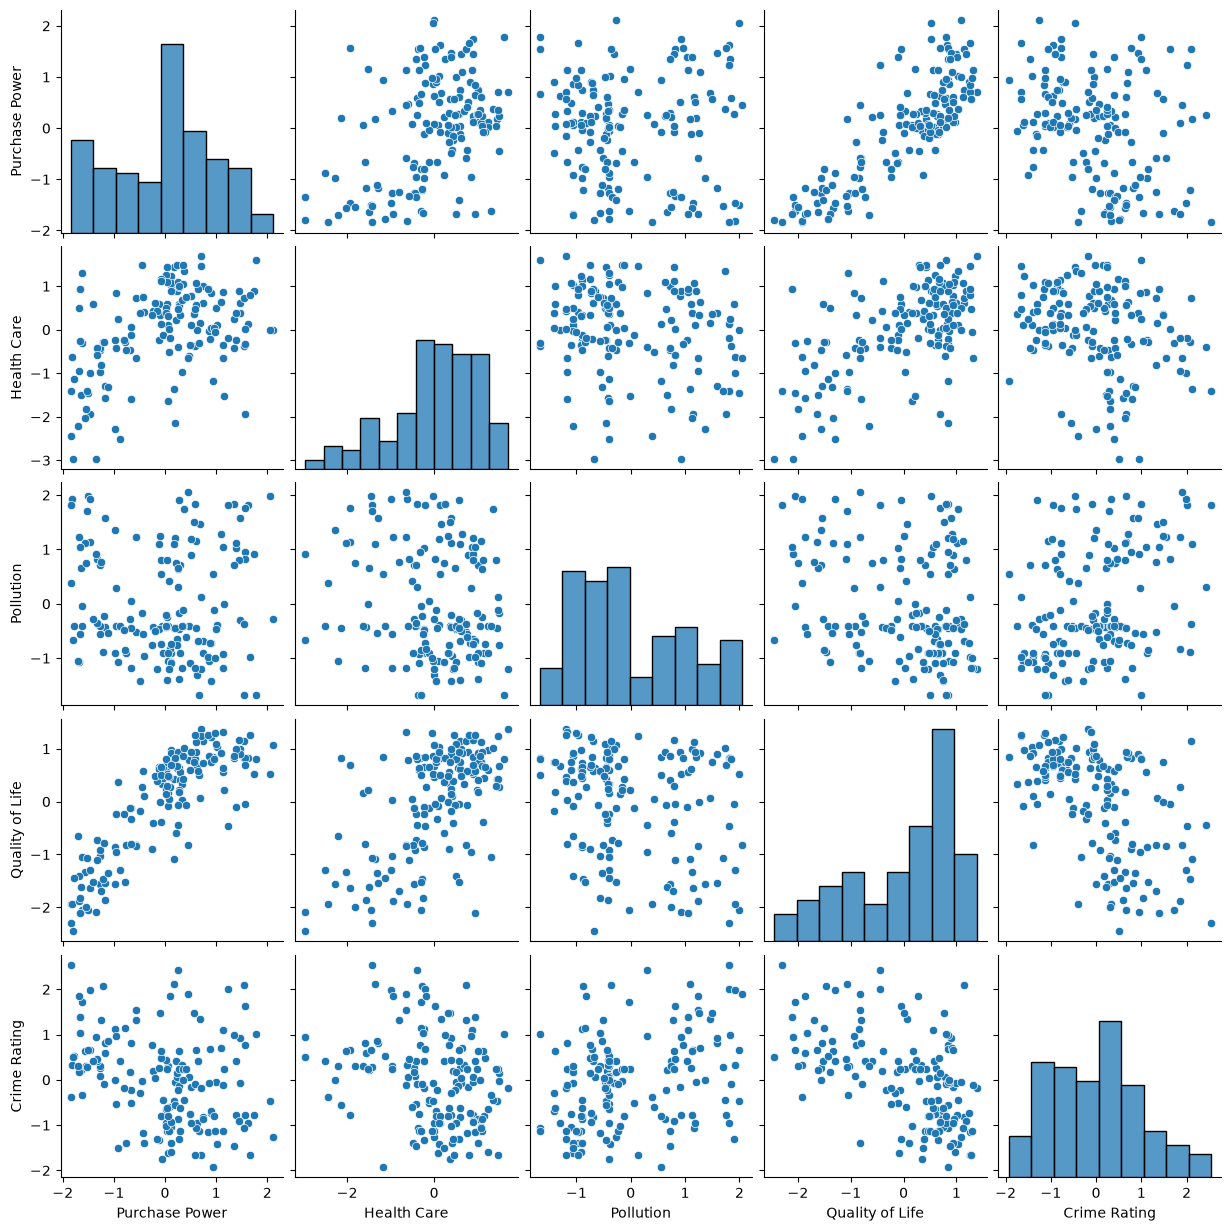

In [8]:
sns.pairplot(df[num_cols])
plt.show()

### 2.2. t-SNE Plot
#### 2.2.1  t-SNE Plot with City Labels

1. Plot a t-SNE plot with random state 88 and a perplexity of 20. (You should have explored this plot in Assignment 5). *(I'd suggest using `plt.figure(figsize=(15,10))` for proper scaling to more easily assess cluster shapes.)*
2. Color code by the region labels.
3. Also, overlay a label with each city name on top of each point.

In [10]:
from sklearn.manifold import TSNE

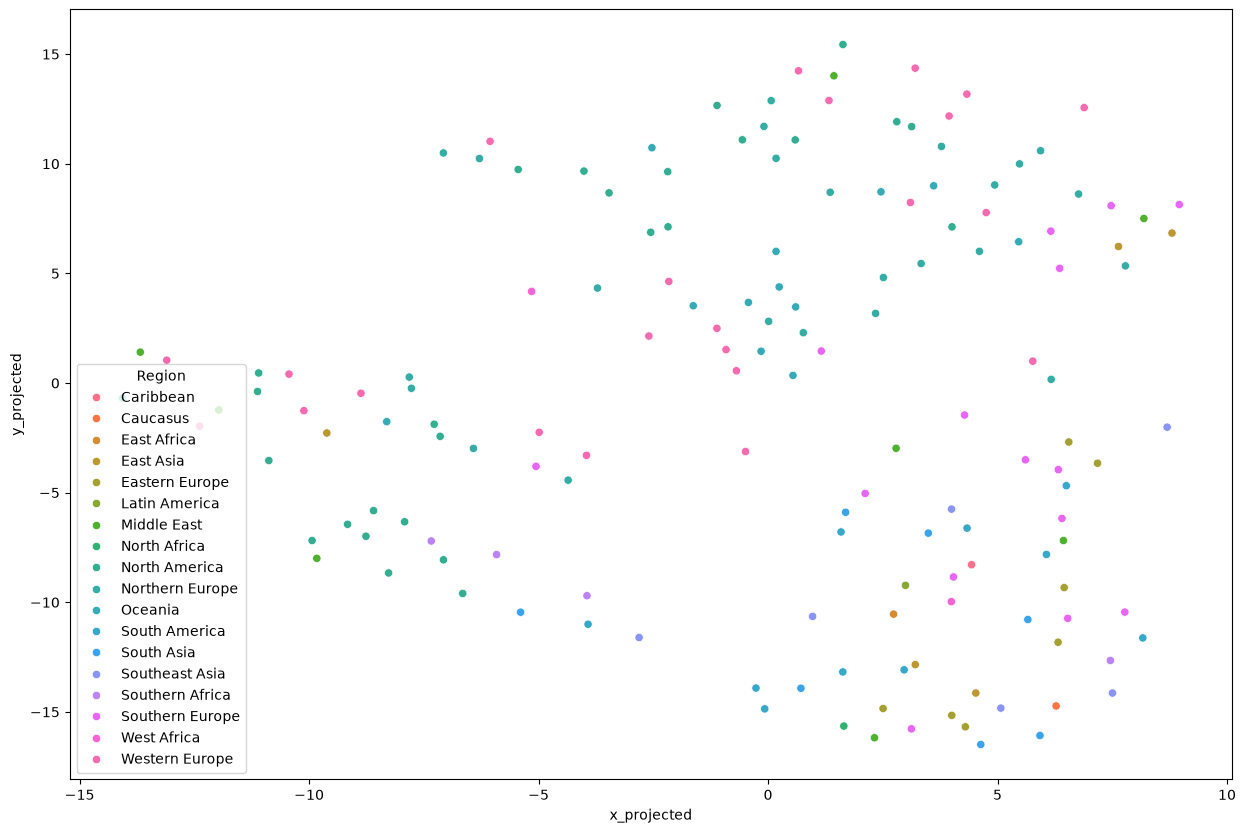

In [14]:
tsne = TSNE(n_components=2, perplexity=20, random_state=88)
data_tsne = tsne.fit_transform(df[num_cols])

df_tsne = pd.DataFrame(data_tsne, columns=["x_projected", "y_projected"], index=df.index)
df_combo = pd.concat([df, df_tsne], axis=1)

plt.figure(figsize=(15, 10))
sns.scatterplot(x="x_projected", y="y_projected", hue="Region", data=df_combo)
plt.show()

#### 2.2.2 Clustering Properties

1. Does the t-SNE plot *clearly* suggest that all suggested clusters are well-separated?
2. Does the t-SNE plot suggest that some of our clusters may be slightly larger or perhaps elongated?

1. No. Many points overlap, and the clusters are not clearly separated. But there's a very rough shape of 3 clusters

2. Yes. Some clusters appear larger or more elongated than others.

### 2.3. Outliers

#### 2.3.1. Single Linkage Dendrogram 

Cluster your scaled dataset using hierarchical agglomerative clustering with **single linkage** and show the dendrogram. The bottom of your dendrogram tree should be labeled with the `City` names.

You should be able to SEE the city names. You can resize the image to help display the city names more visibly by using the following code BEFORE the `dendrogram()` function.

`plt.subplots(figsize=(20, 35))`

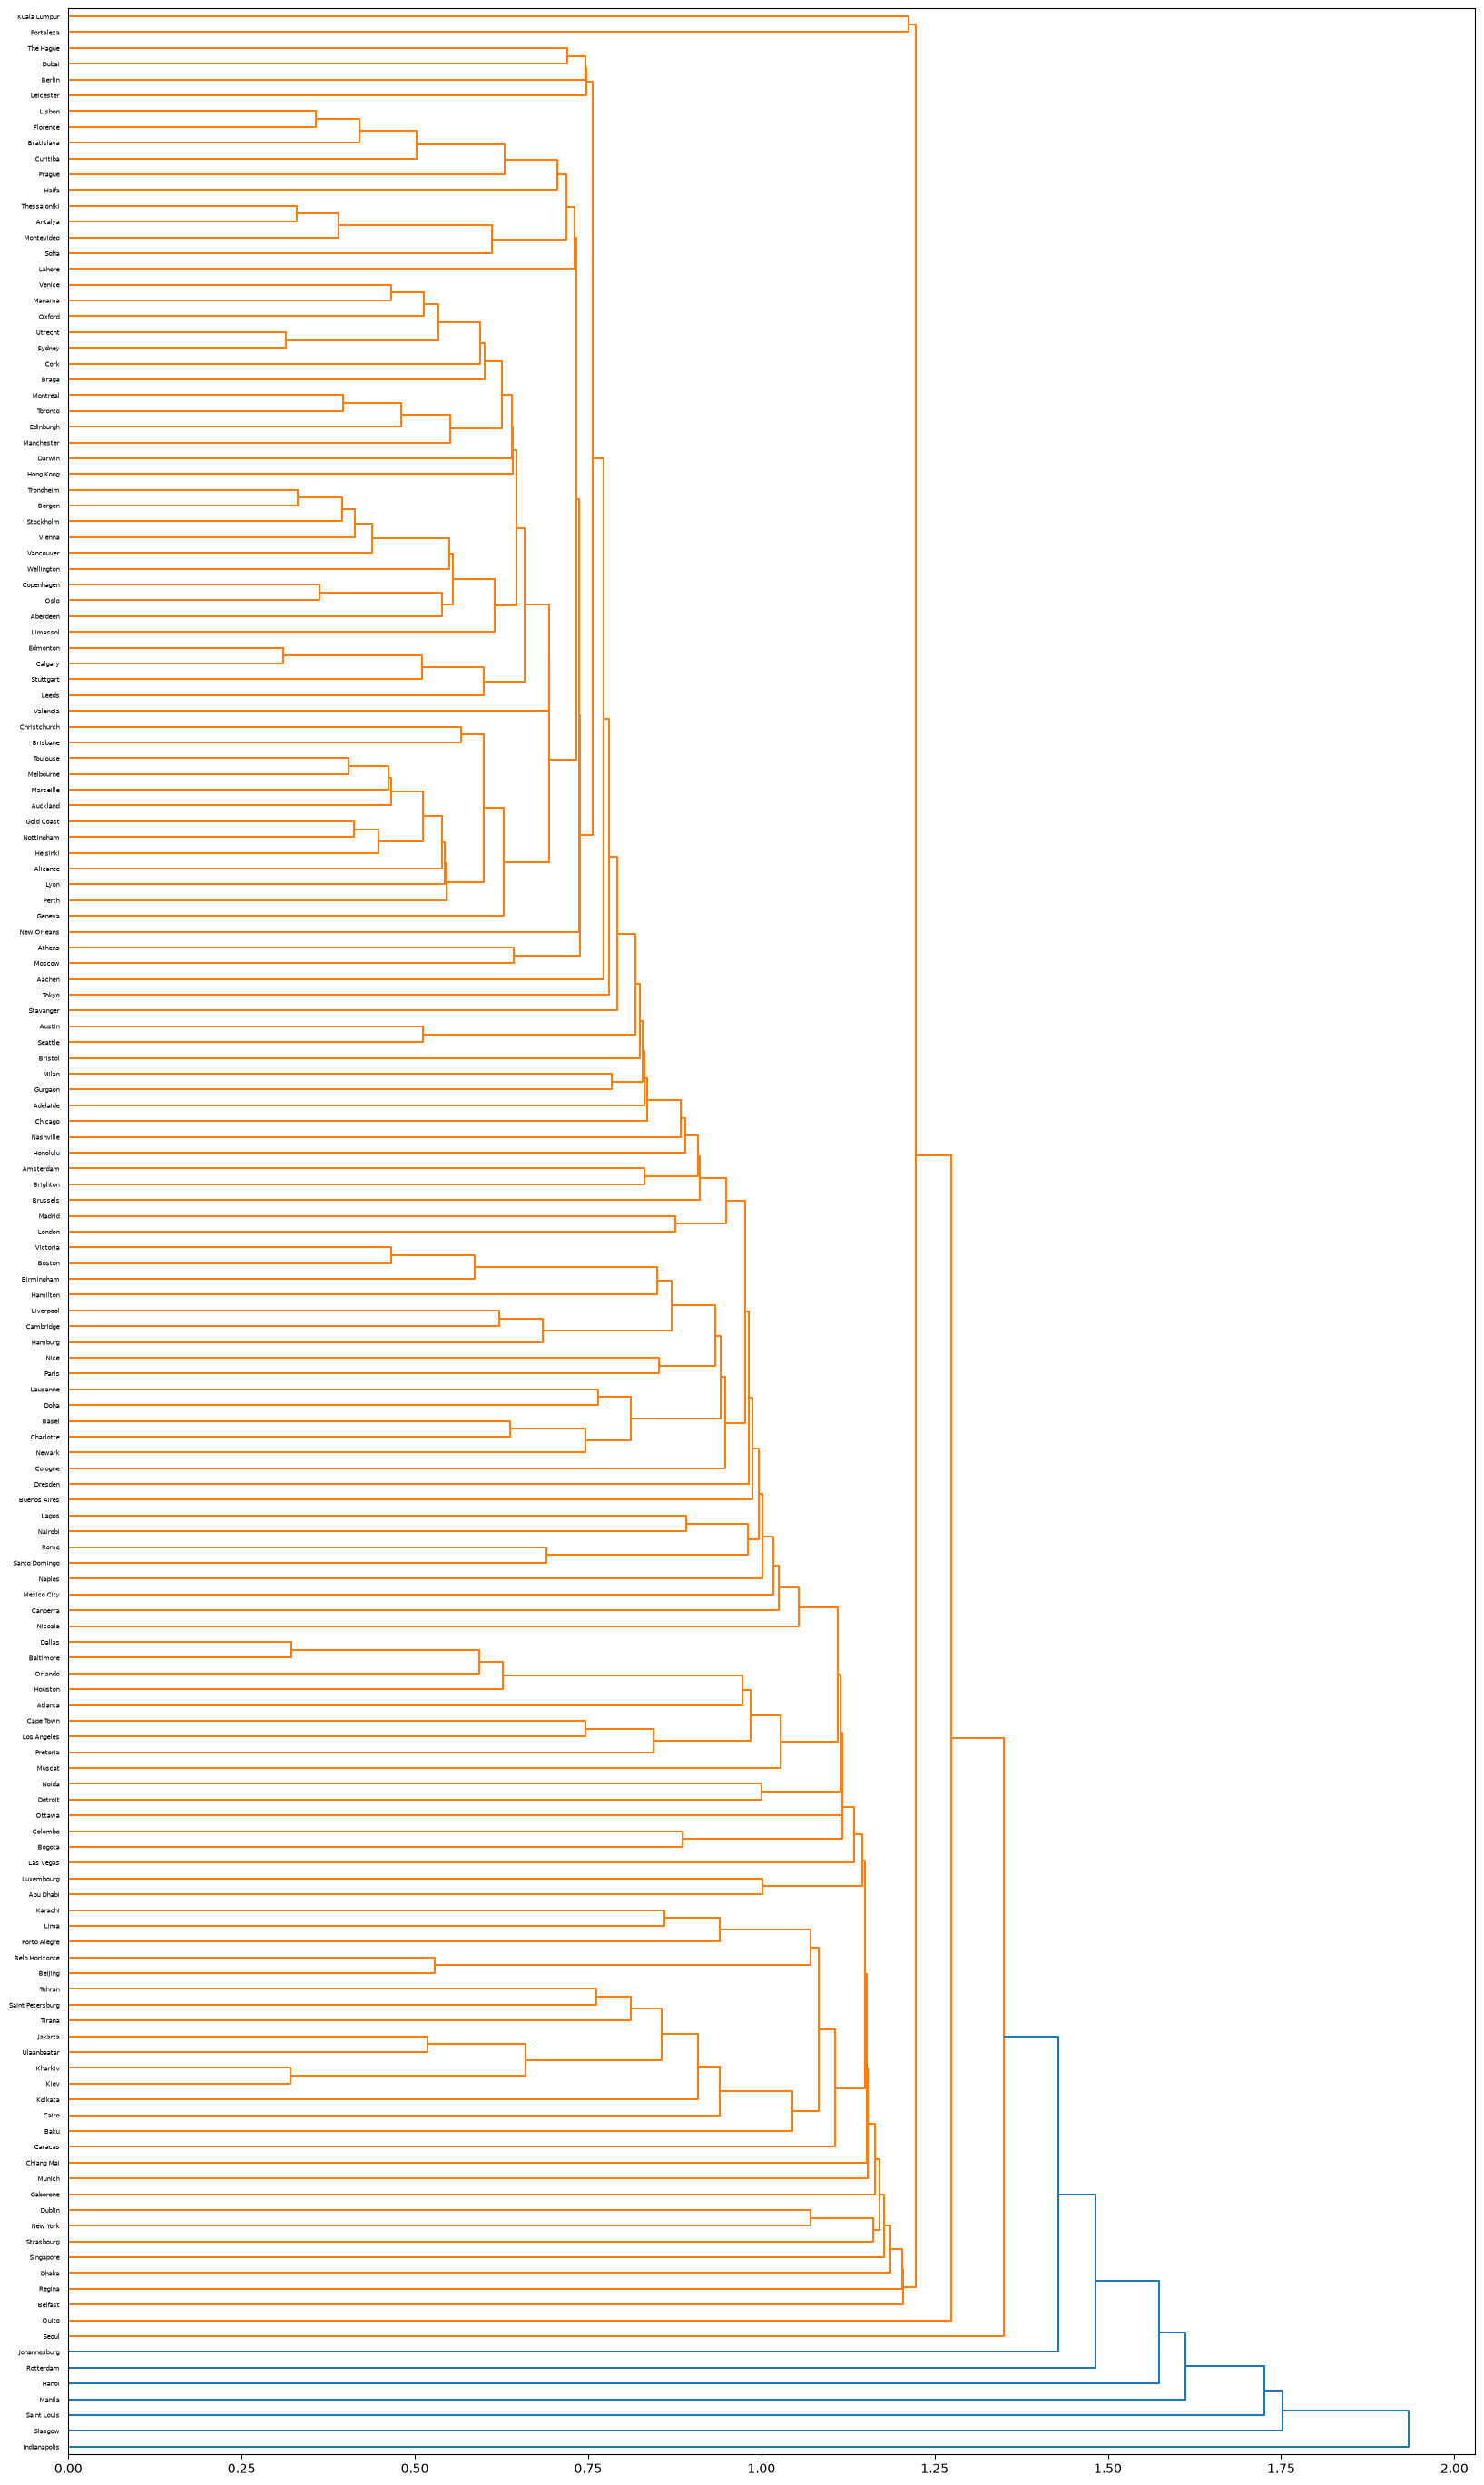

In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(df[num_cols], method='single')

plt.figure(figsize=(20, 35))
dendrogram(Z, labels=df['City'].values, orientation='right')
plt.show()

#### 2.3.2. Outliers

1. Use the dendrogram above to determine which city is the furthest away from it's nearest neighbor in this dataset.
2. Would consider this observation to be a *dramatic* outlier in this dataset? Explain.

1. Indianapolis.

2. No. Although Indianapolis is the furthest from its nearest neighbor, its distance is not dramatically larger than those of other observations.

#### 2.3.3. Seattle

Which city is the nearest neigbhor of Seattle in this dataset?

Austin

## 3. Suitability of Different Algorithms and Clustering Exploration Techniques

Use the suggestions that we might make based on the plots in #2.1, #2.2, and #2.3 to answer the questions below.

### 3.1. HAC with Single Linkage Suitability

What has been suggested about the dataset so far that *may* make HAC with single linkage unideal for identifying the inherent clusters in the dataset?

The clusters are not well-separated, which may cause a chaining effect in single linkage. This can incorrectly merge different clusters together.

### 3.2. Other HAC Algorithm Suitability

Which linkage function do you think will be the *least* sensitive to the issue that you highlighted in #3.1 above?

Complete linkage, because it uses the maximum distance between clusters, makes it less sensitive to the chaining effect.

## 4. Clustering Algorithm Comparison

To learn about which clusters are most dissimilar to each other in our clusterings, let's use a hierarchical agglomerative clustering algorithm. Let's first consult the average silhouette score.

### 4.1.  Average Silhouette Score Plots

Create 4 average silhouette score plots with this dataset, one for each of the following clustering algorithms:
* Hierarchical agglomerative clustering with single linkage
* Hierarchical agglomerative clustering with average linkage
* Hierarchical agglomerative clustering with complete linkage
* Hierarchical agglomerative clustering with Ward's linkage

Each of your average silhouette score plots should plot the average silhouette score for clusterings created with this algorithm with k=2, k=3, ..., k=11 clusters, respectively.

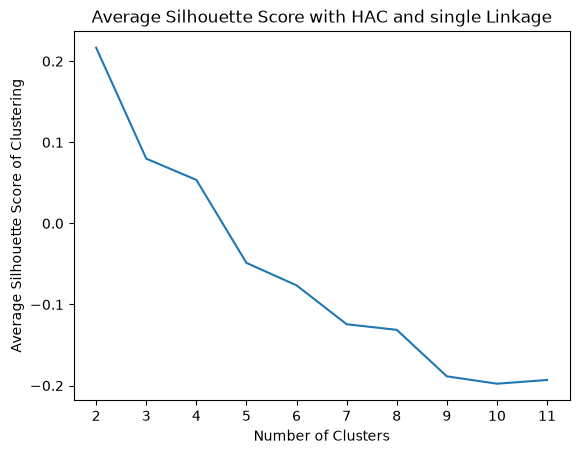

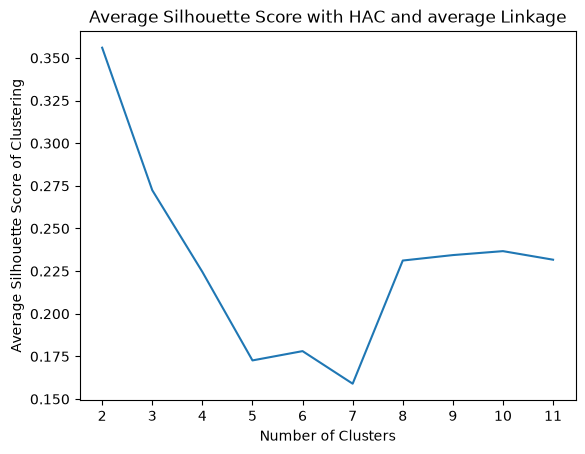

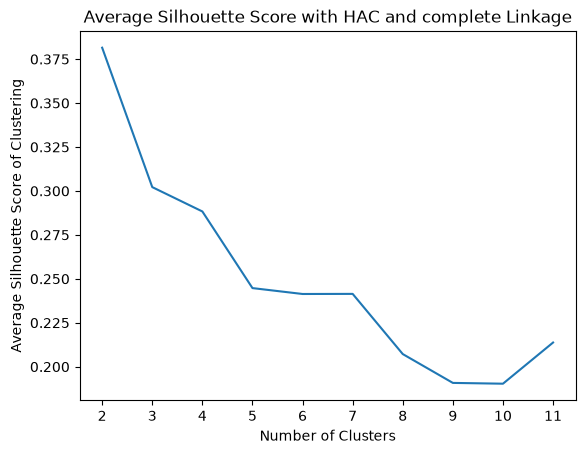

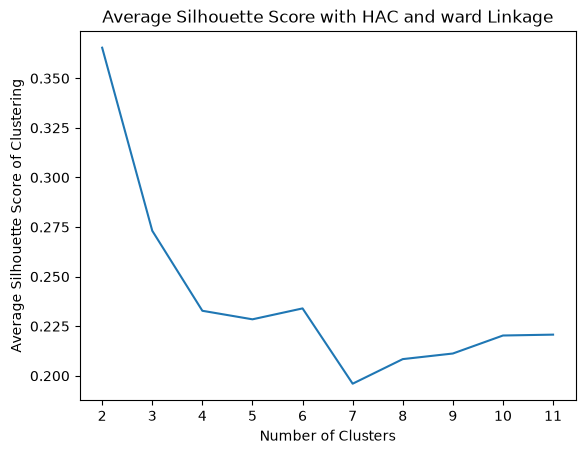

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

for link in ['single', 'average', 'complete', 'ward']:
    avg_ss = []

    for k in range(2, 12):
        hac = AgglomerativeClustering(n_clusters=k, linkage=link)
        Y_pred = hac.fit_predict(df[num_cols])

        avg_ss.append(silhouette_score(df[num_cols], Y_pred))

    plt.plot(range(2, 12), avg_ss)
    plt.title('Average Silhouette Score with HAC and %s Linkage' % link)
    plt.xlabel('Number of Clusters')
    plt.ylabel('Average Silhouette Score of Clustering')
    plt.xticks(range(2, 12))
    plt.show()

### 4.2. Which clustering algorithm and k?

1. Which hierarchical agglomerative clustering algorithm and cluster number are the plots above suggesting will yield the best cohesion and separation?
2. Does this cluster number that you selected agree with the number of clusters suggested in the t-SNE plot?

1. HAC with complete linkage and k=2 gives the best cohesion and separation because it has the highest average silhouette score, about 0.38.

2. No, the t-SNE plot seems to show about three groups, so it does not clearly agree with k=2

## 5. Hierarchical Agglomerative Clustering with Single Linkage

Let's try out hierarchical agglomerative clustering with single linkage.

### 5.1.  Dendrogram

Create a dendrogram using hierarchical agglomerative clustering with single linkage for the dataset. 
* Label the points with the 'City' column.
* Make sure you are able to read the city labels in your dendrogram.

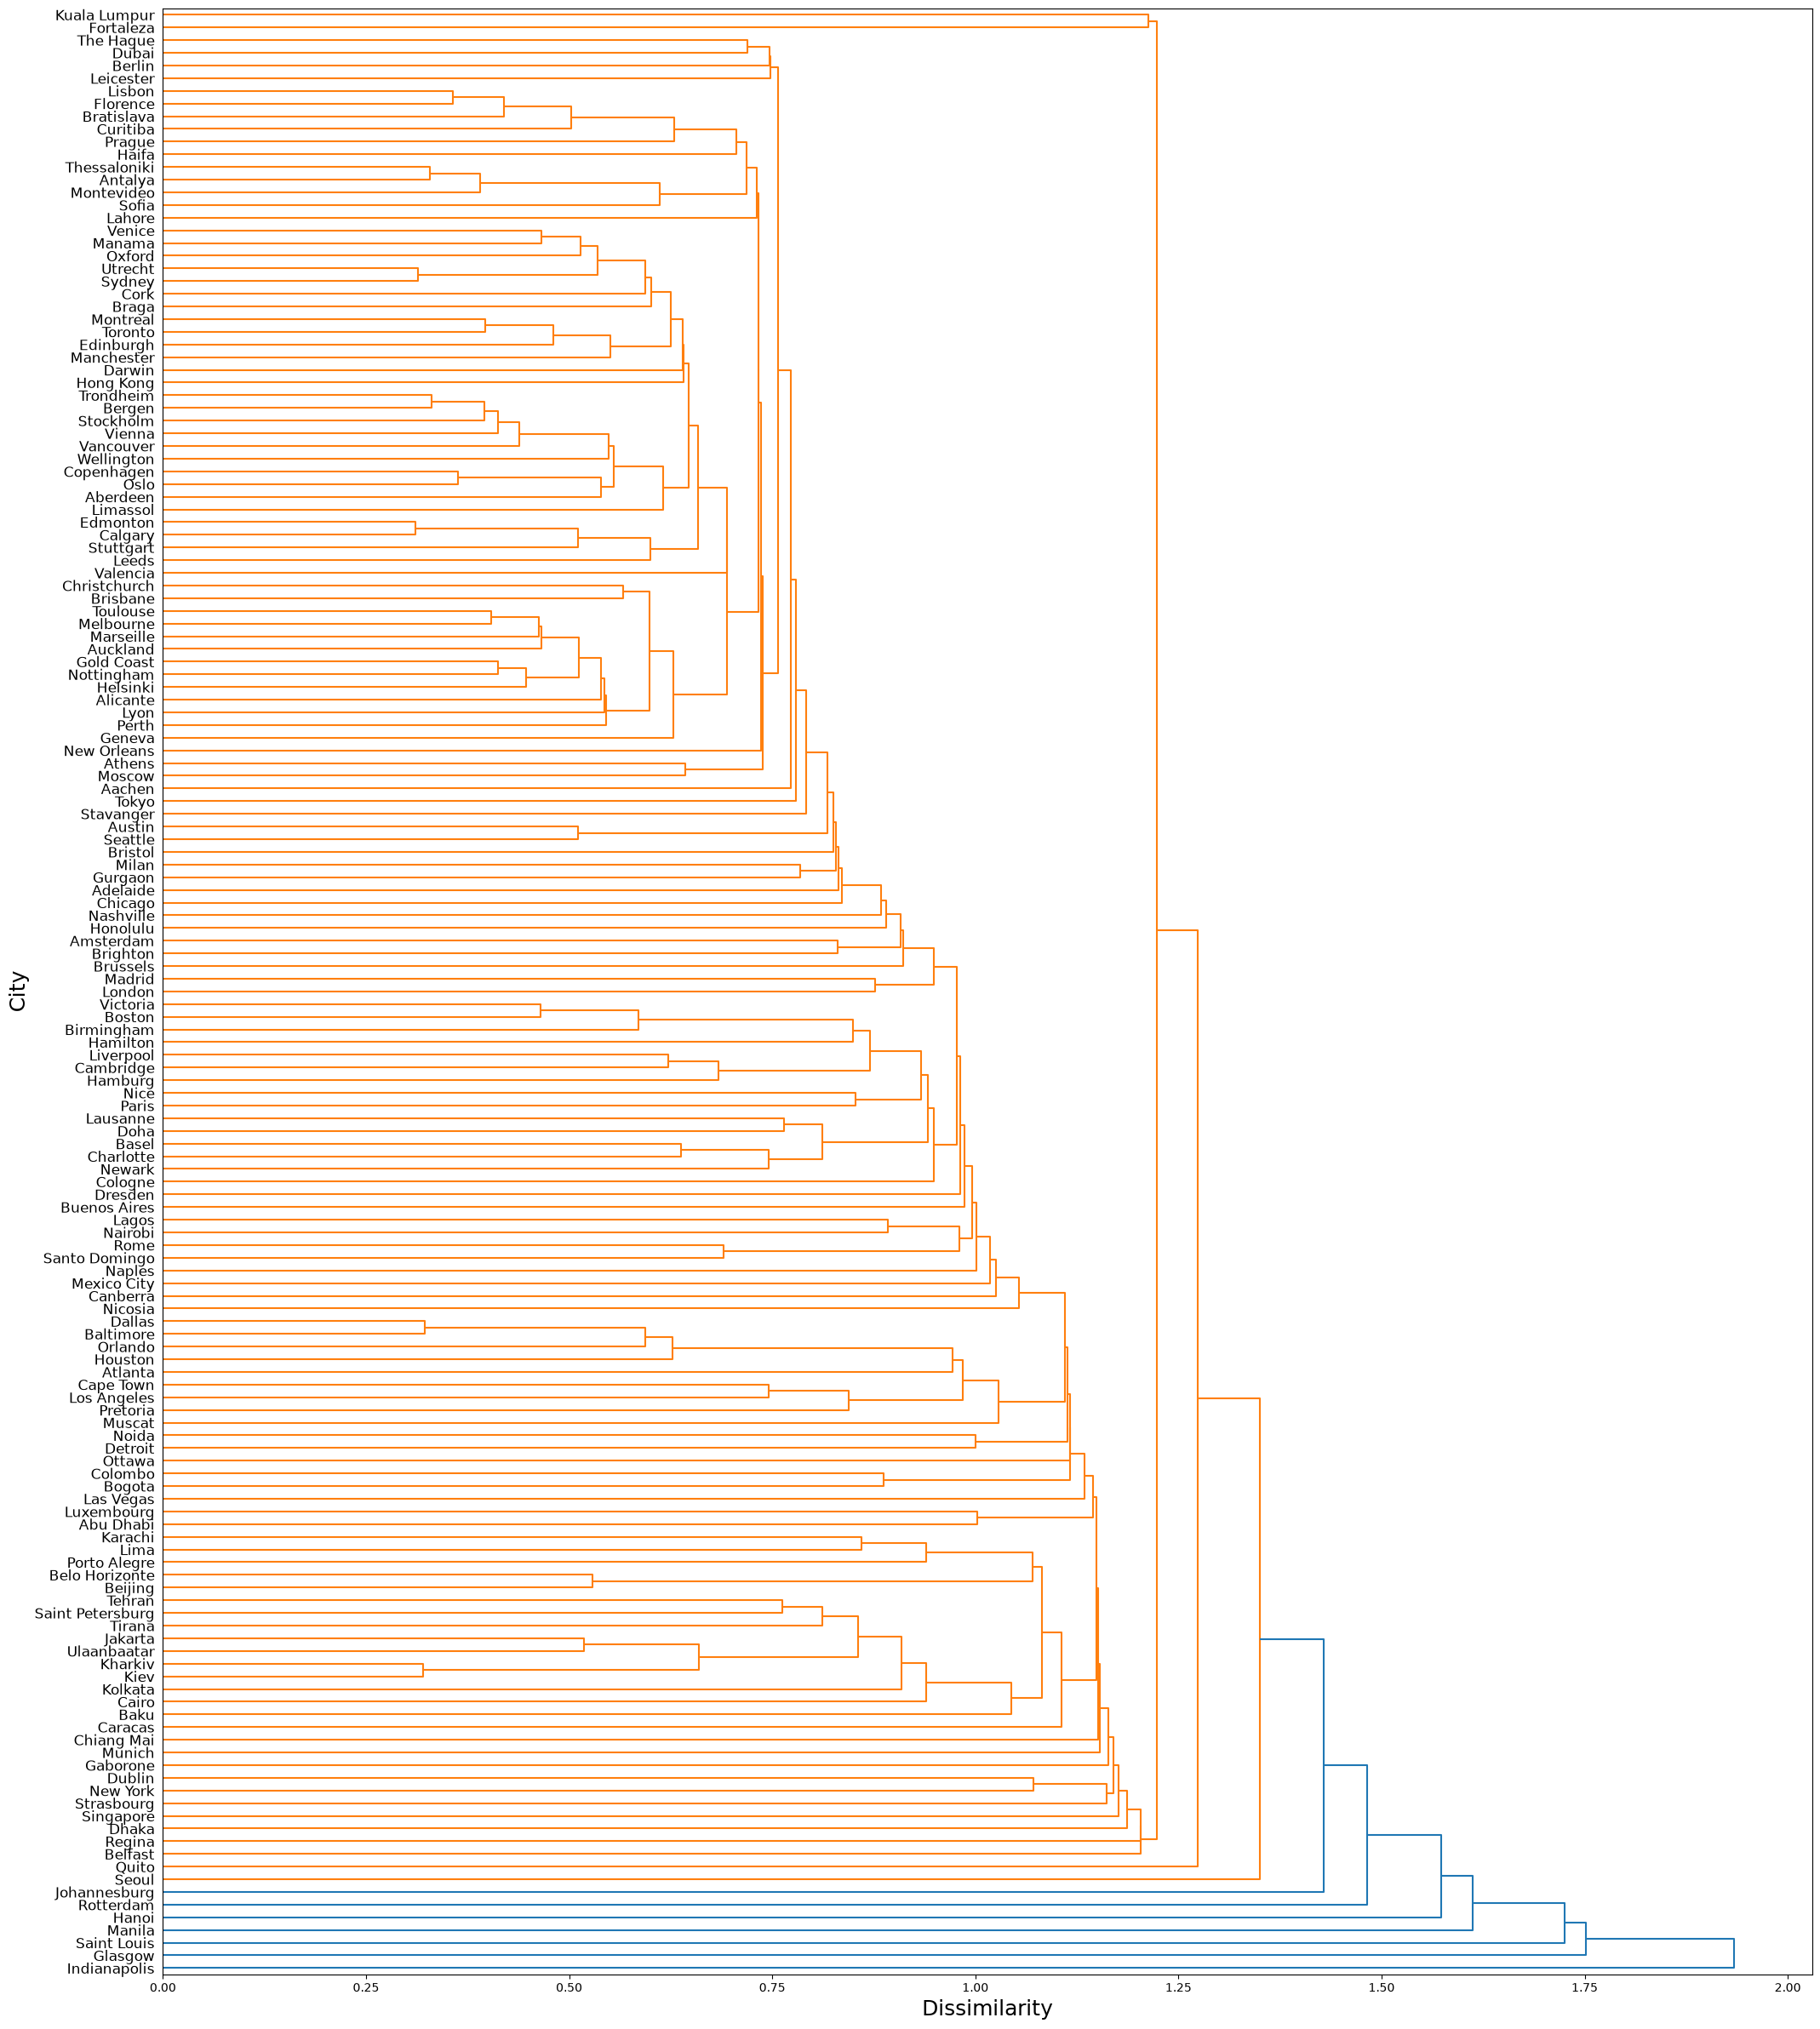

In [20]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

dm = pdist(df[num_cols], metric='euclidean')
Z = linkage(dm, method='single')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', labels=df['City'].array, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('City', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

### 5.2. t-SNE Individual Clustering Visualization

Then for each of the clusterings with k=2,k=3,...,k=11 clusters, color code the points in your selected t-SNE plot with the respective cluster labels.

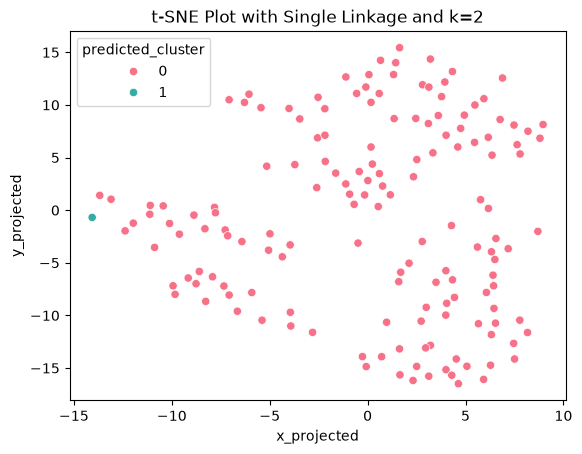

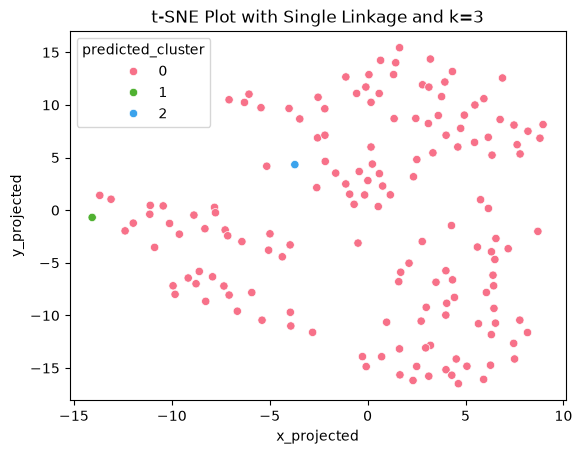

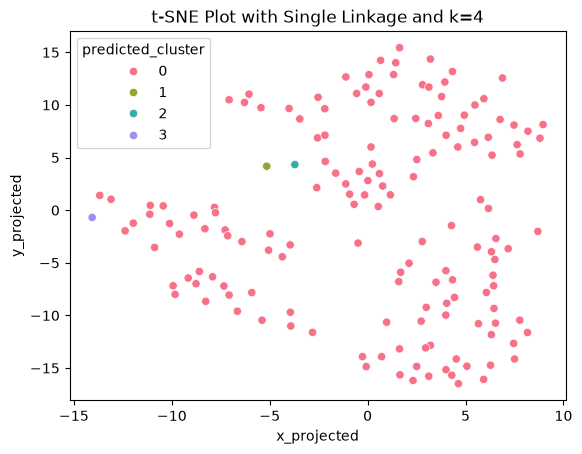

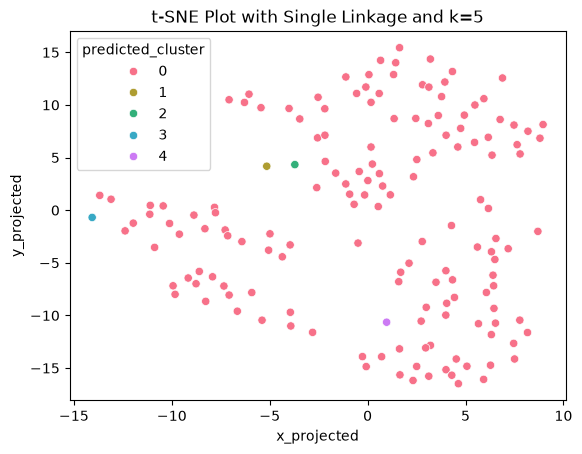

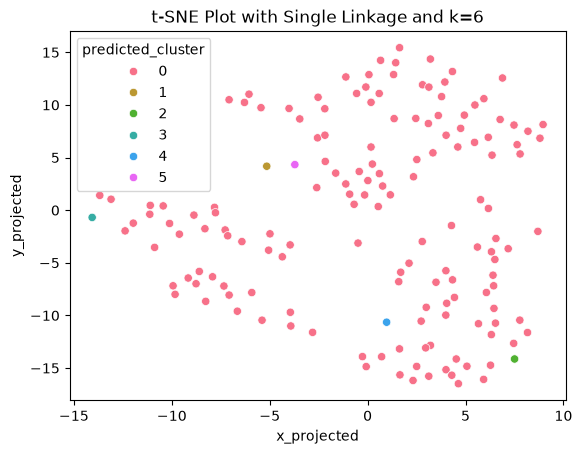

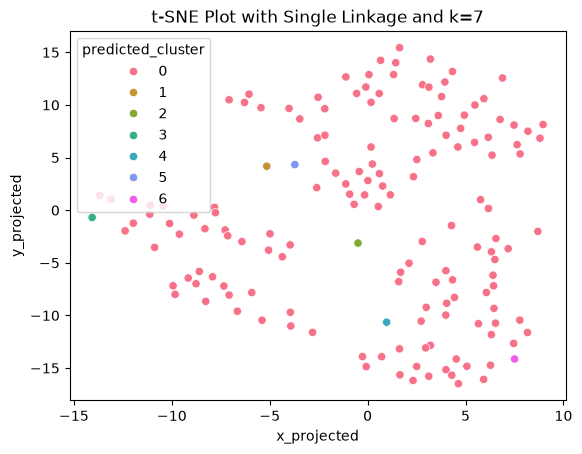

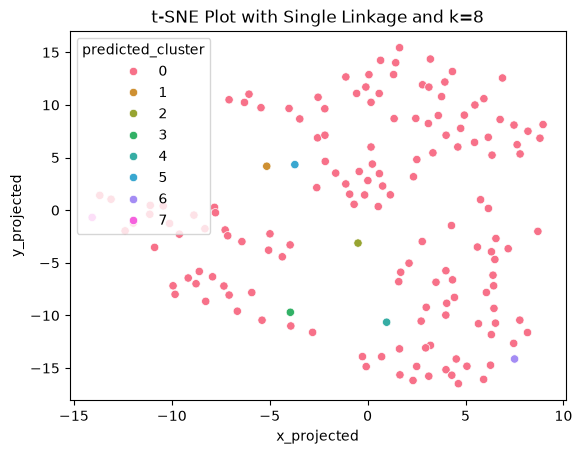

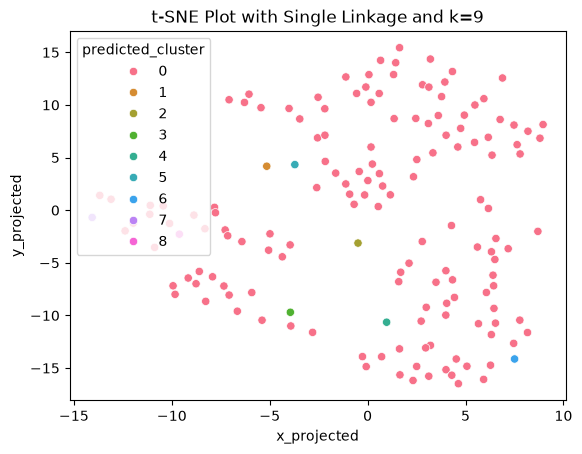

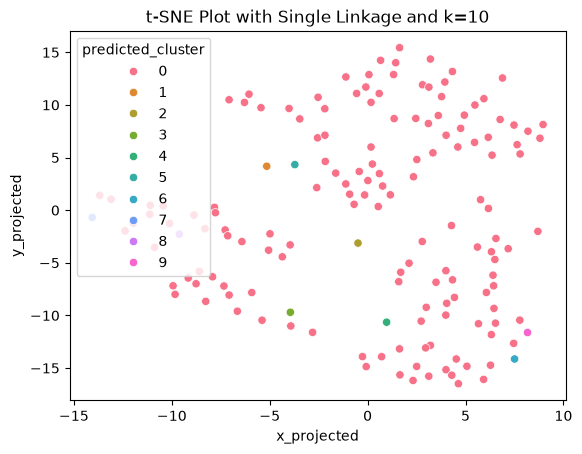

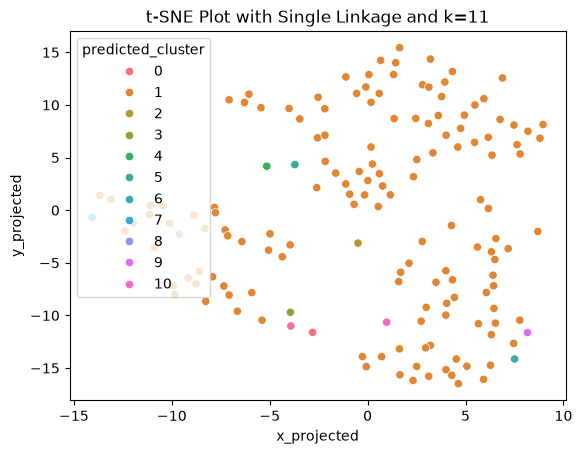

In [39]:
for k in range(2, 12):
    hac = AgglomerativeClustering(n_clusters=k, linkage='single')
    df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])

    sns.scatterplot( x='x_projected', y='y_projected', hue='predicted_cluster',palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Single Linkage and k=%s' % k)
    plt.show()

## 6. Hierarchical Agglomerative Clustering with Complete Linkage

Let's try out hierarchical agglomerative clustering with complete linkage.

### 6.1.  Dendrogram

Create a dendrogram using hierarchical agglomerative clustering with complete linkage for the dataset. 
* Label the points with the 'City' column.
* Make sure you are able to read the city labels in your dendrogram.

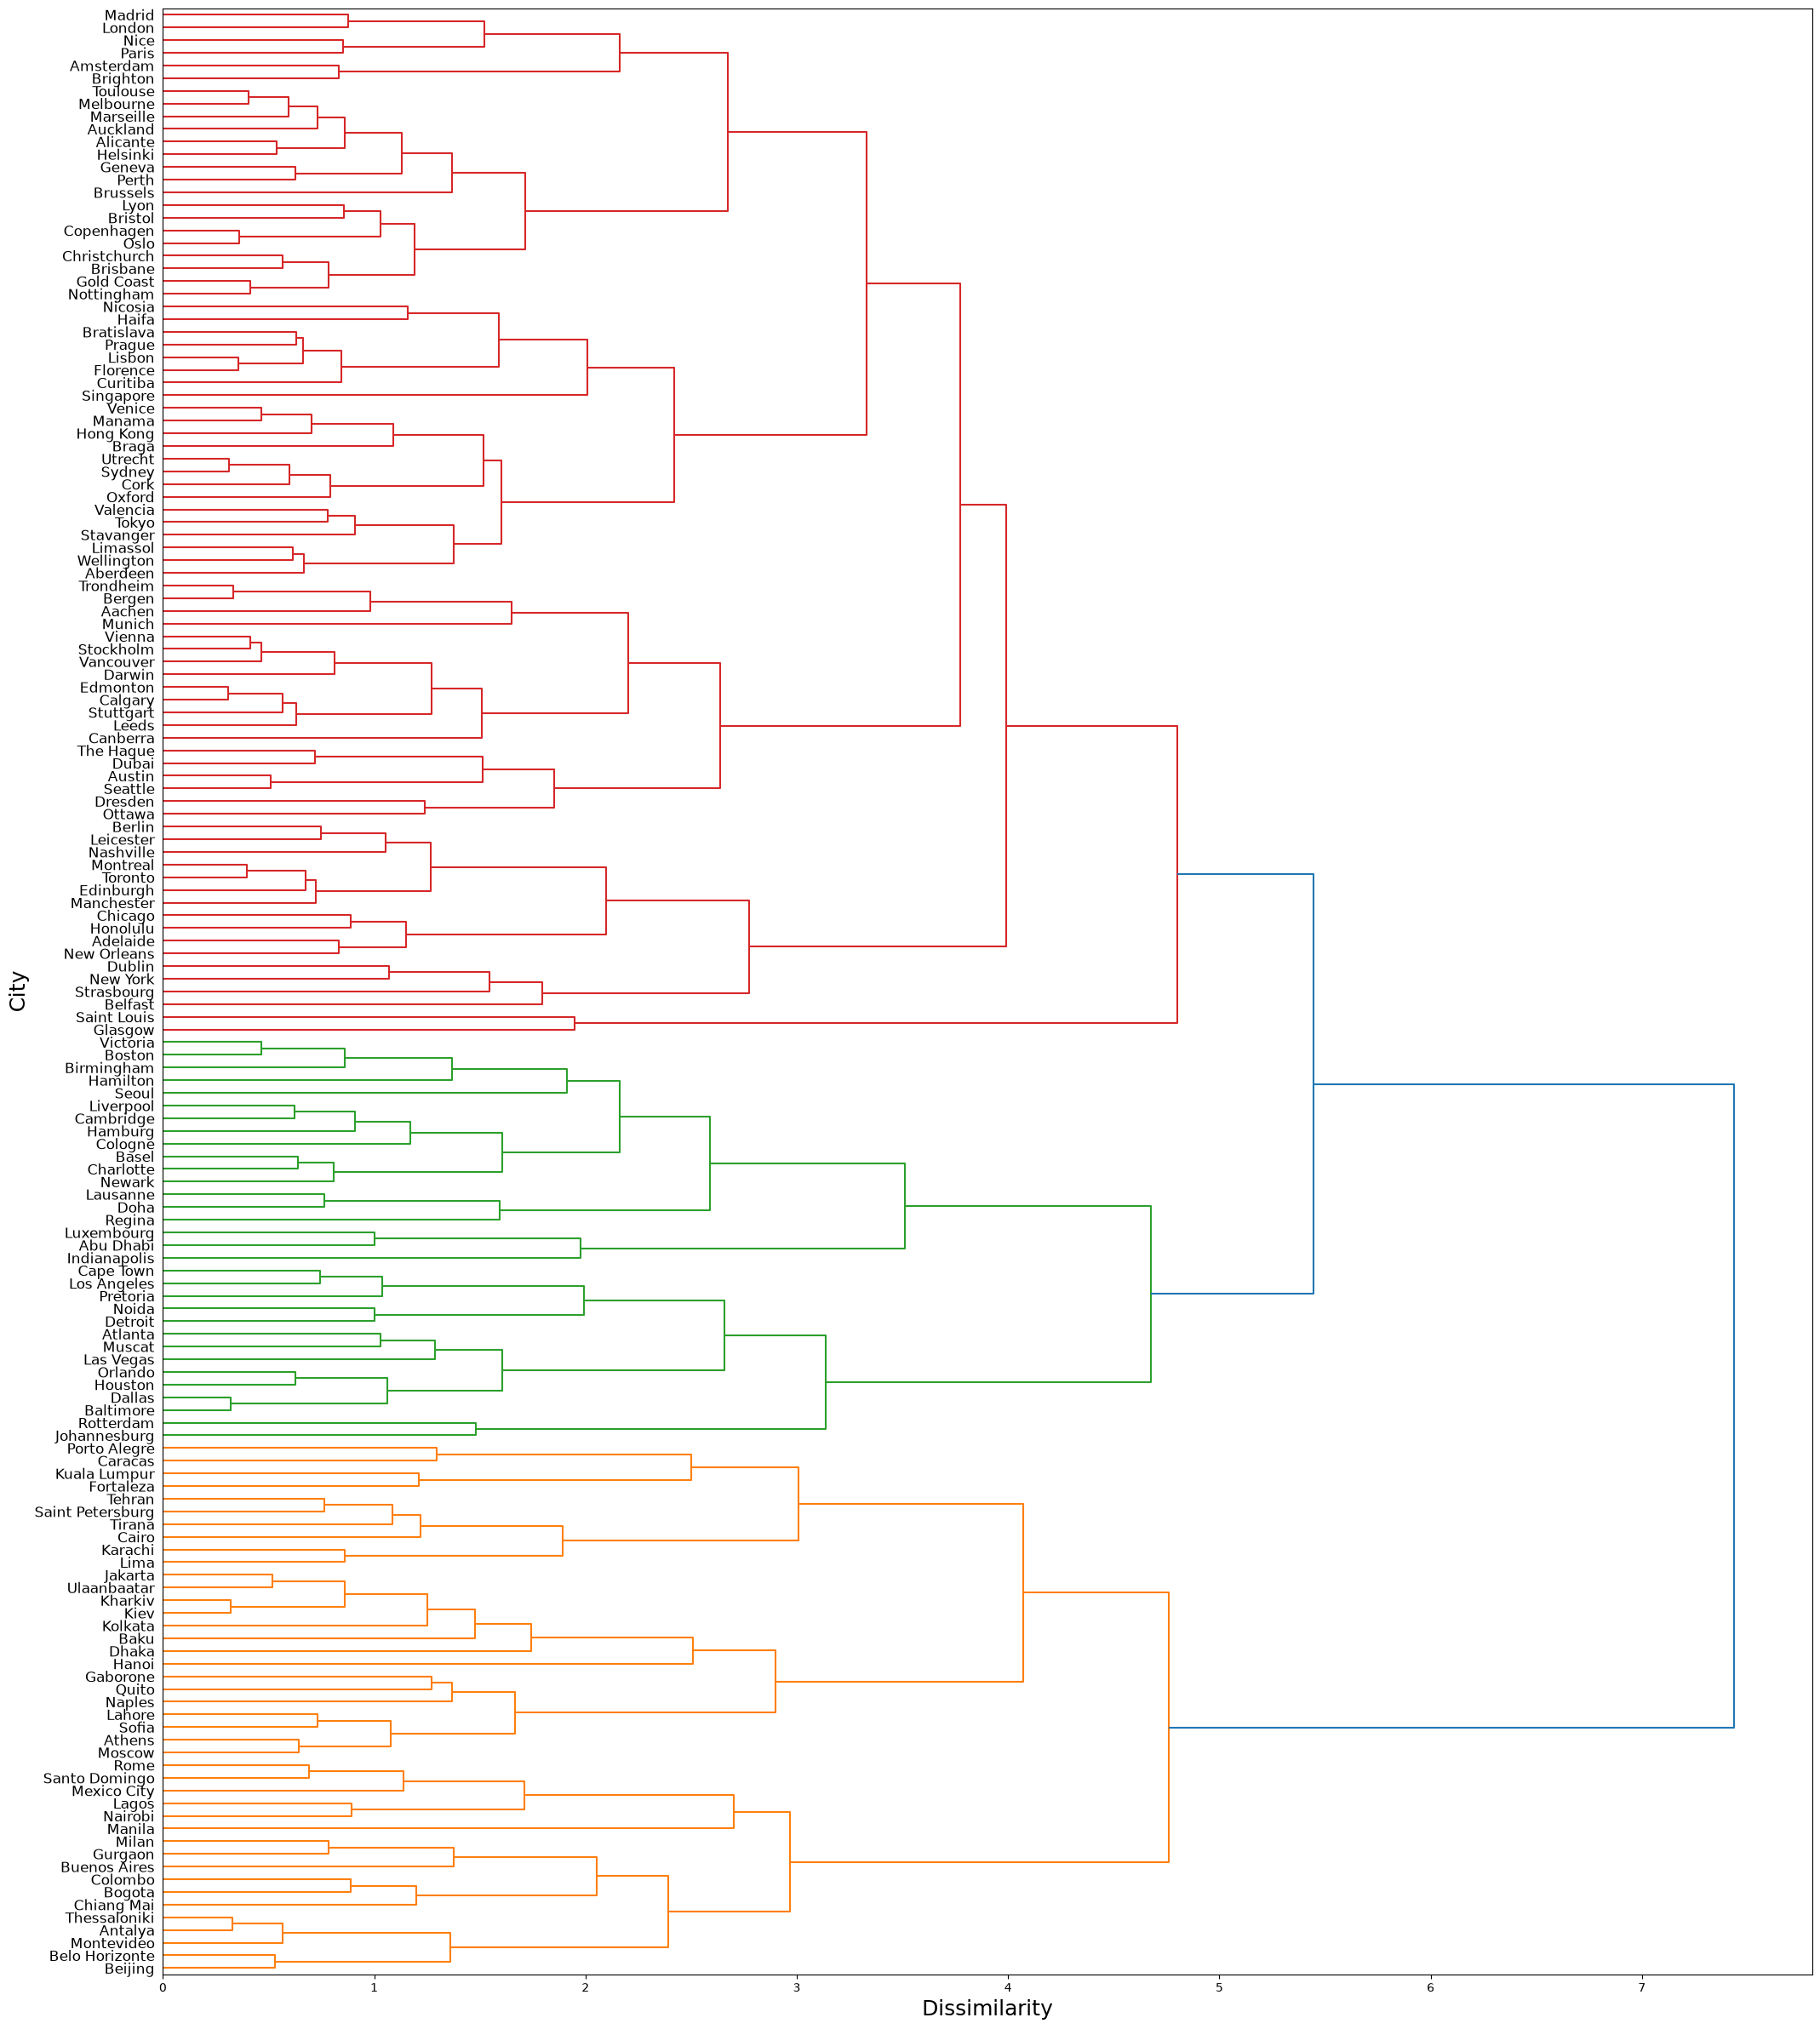

In [27]:
dm = pdist(df[num_cols], metric='euclidean')
Z = linkage(dm, method='complete')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', labels=df['City'].array, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('City', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

### 6.2. t-SNE Individual Clustering Visualization

Then for each of the clusterings with k=2,k=3,...,k=11 clusters, color code the points in your selected t-SNE plot with the respective cluster labels.

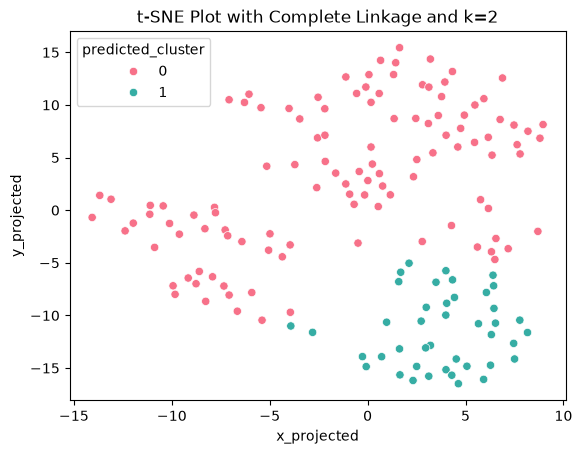

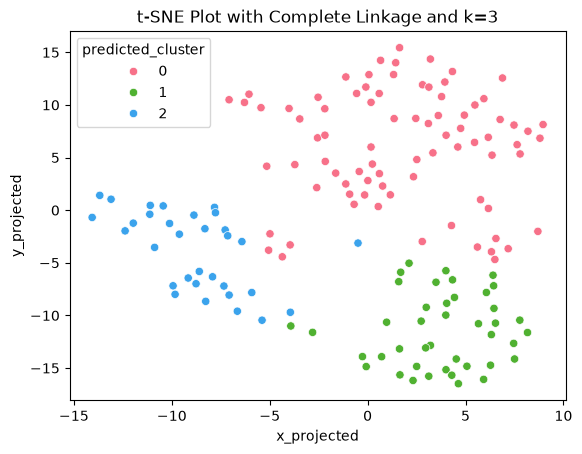

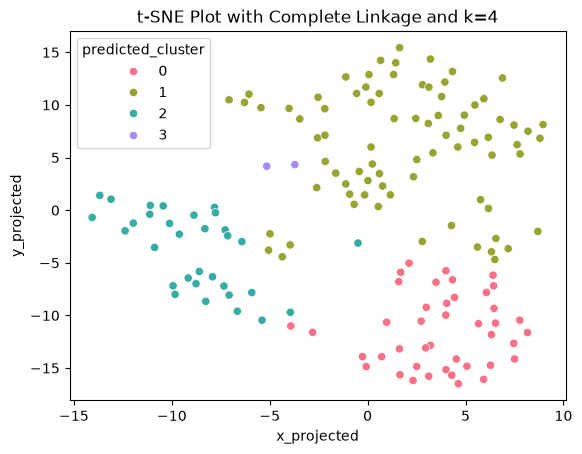

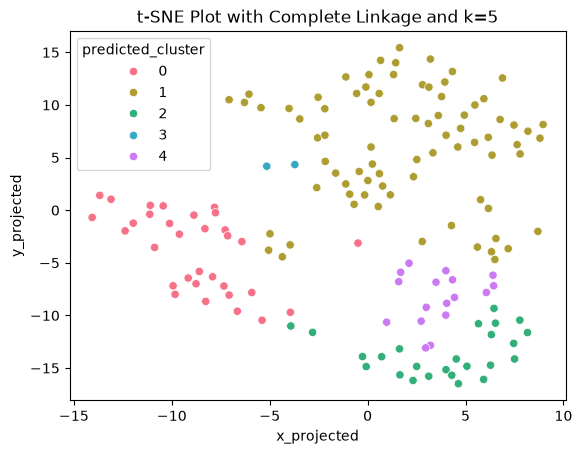

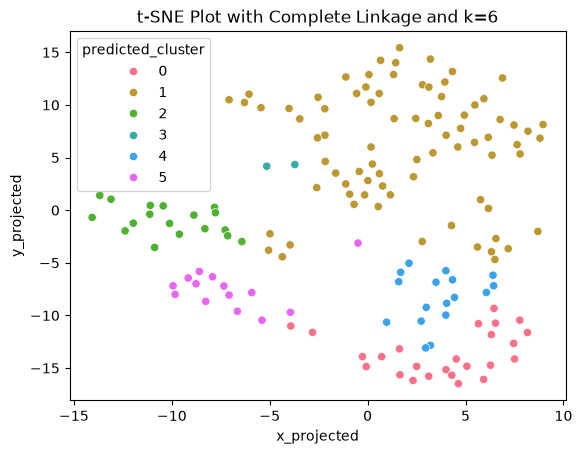

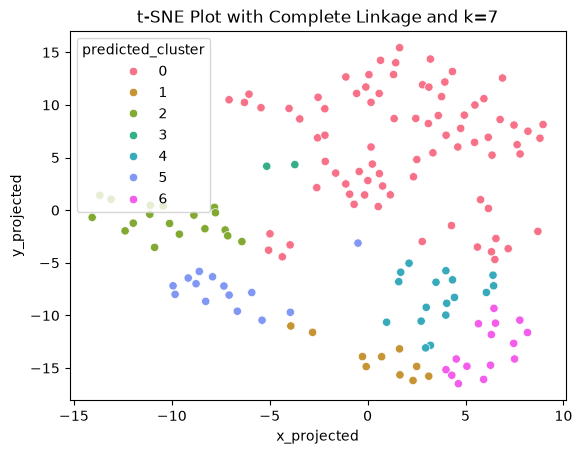

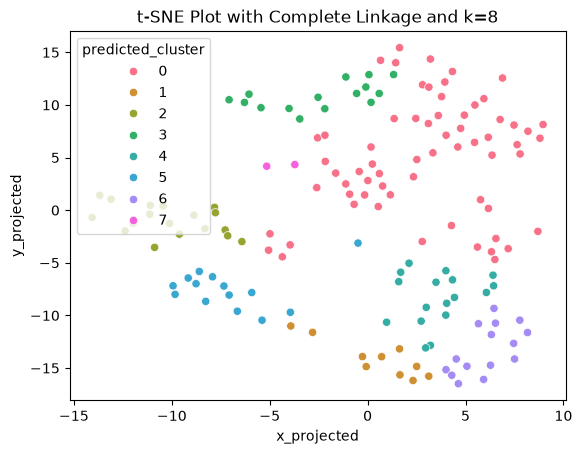

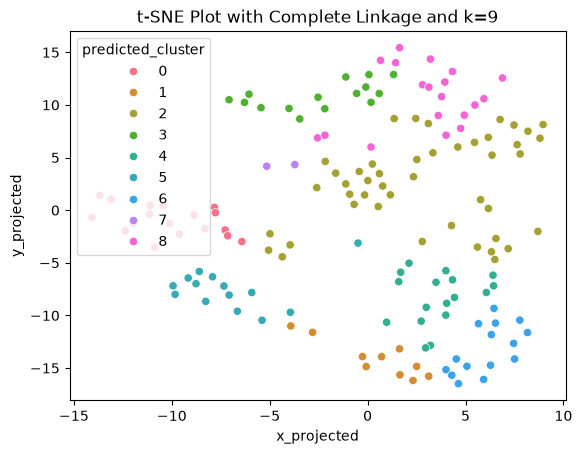

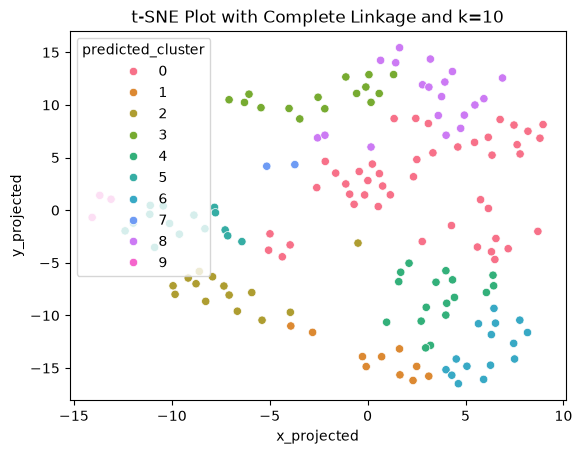

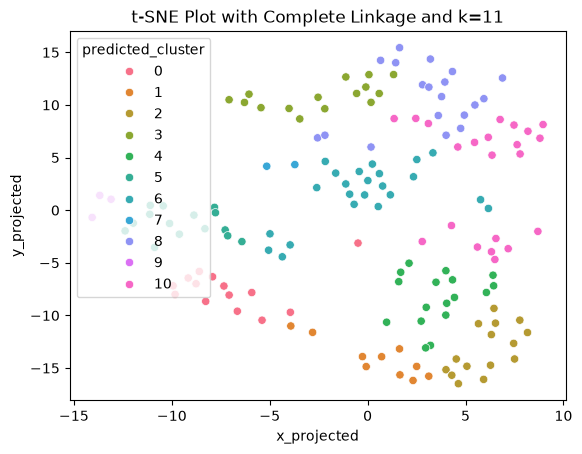

In [38]:
for k in range(2, 12):
    hac = AgglomerativeClustering(n_clusters=k, linkage='complete')
    df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])

    sns.scatterplot(x='x_projected',y='y_projected',hue='predicted_cluster',palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Complete Linkage and k=%s' % k)
    plt.show()

## 7. Hierarchical Agglomerative Clustering with Average Linkage

Let's try out hierarchical agglomerative clustering with average linkage.

### 7.1.  Dendrogram

Create a dendrogram using hierarchical agglomerative clustering with average linkage for the dataset. 
* Label the points with the 'City' column.
* Make sure you are able to read the city labels in your dendrogram.

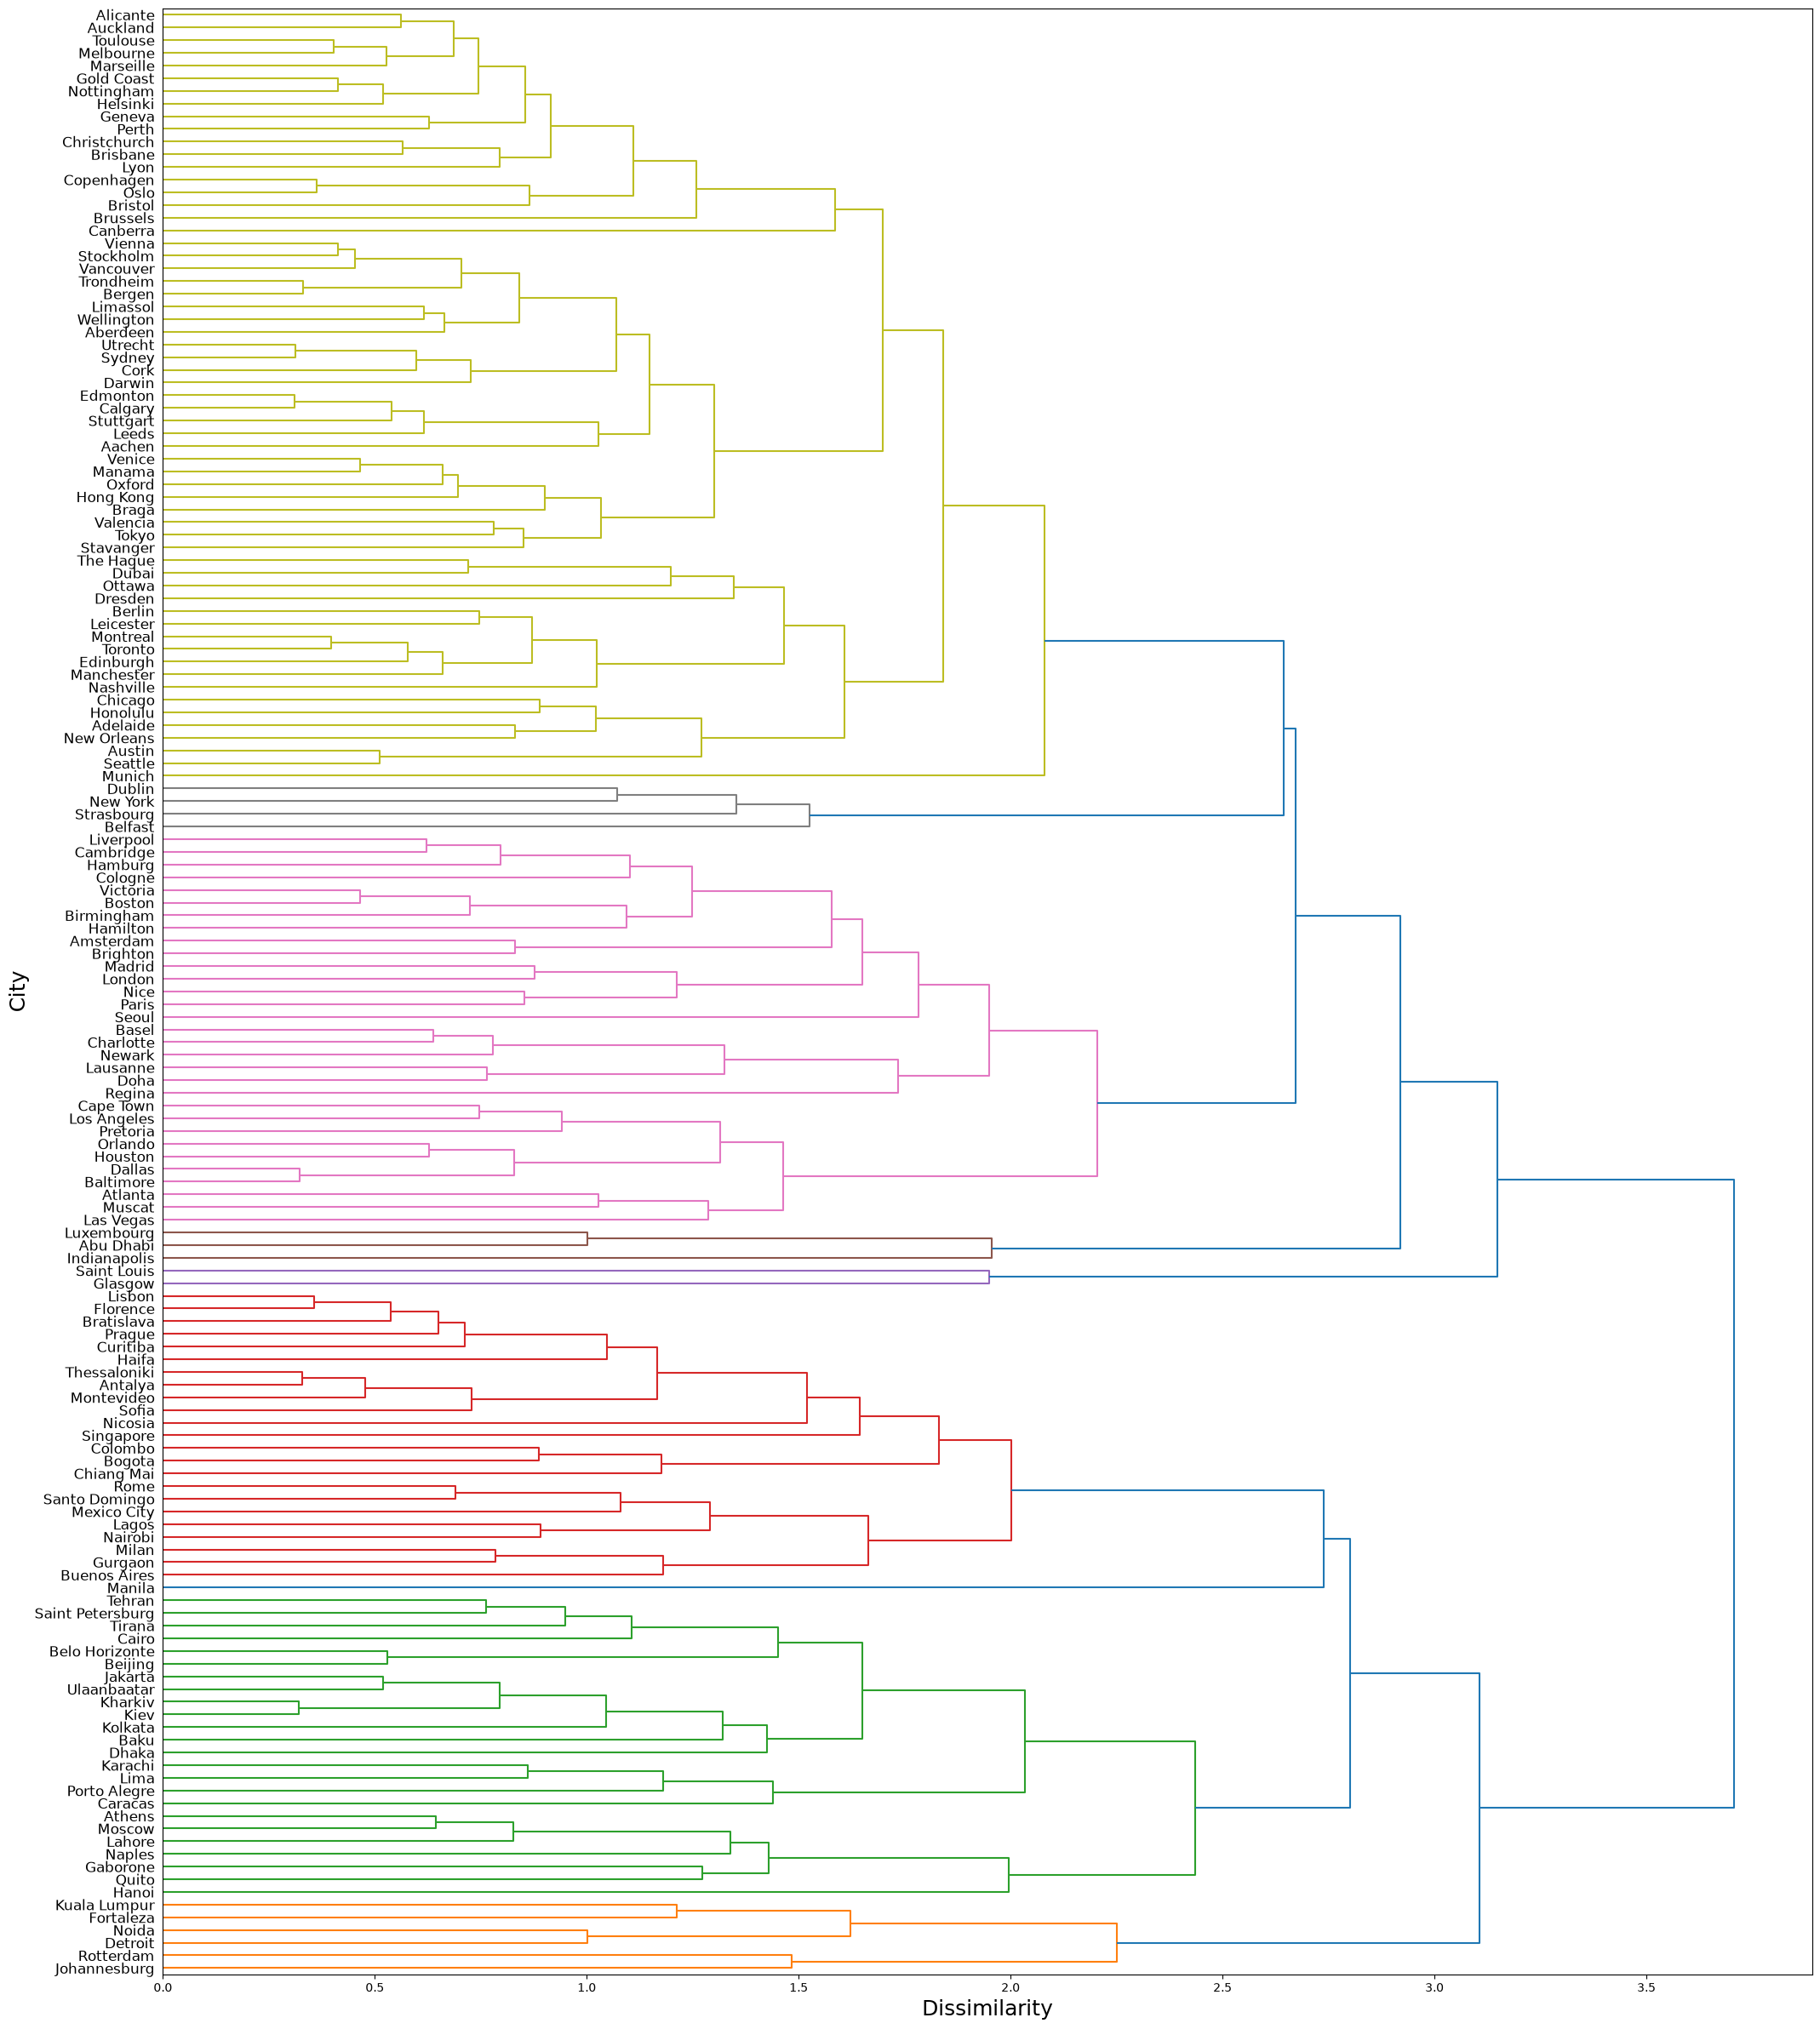

In [36]:
dm = pdist(df[num_cols], metric='euclidean')
Z = linkage(dm, method='average')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', labels=df['City'].array, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('City', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

### 7.2. t-SNE Individual Clustering Visualization

Then for each of the clusterings with k=2,k=3,...,k=11 clusters, color code the points in your selected t-SNE plot with the respective cluster labels.

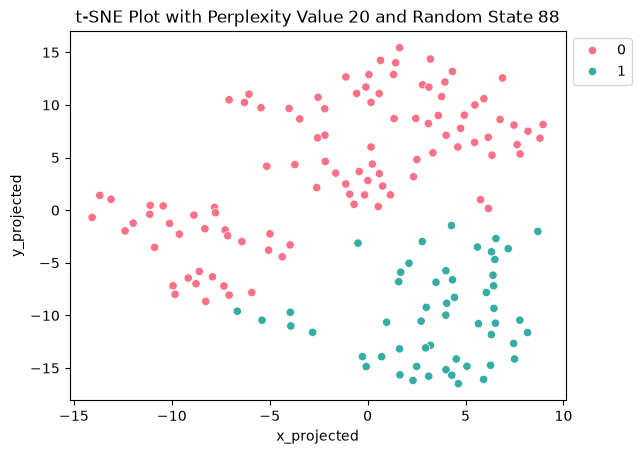

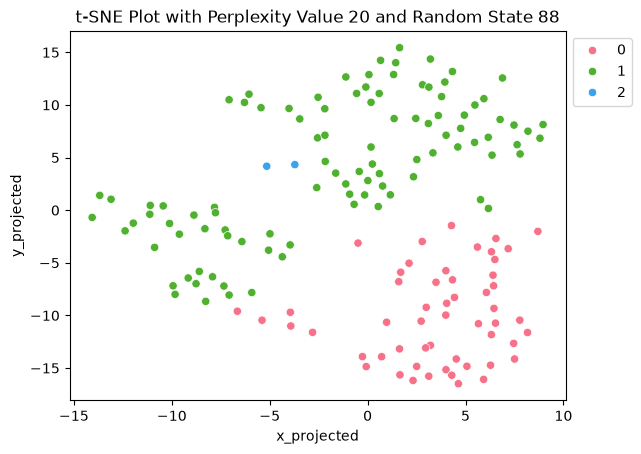

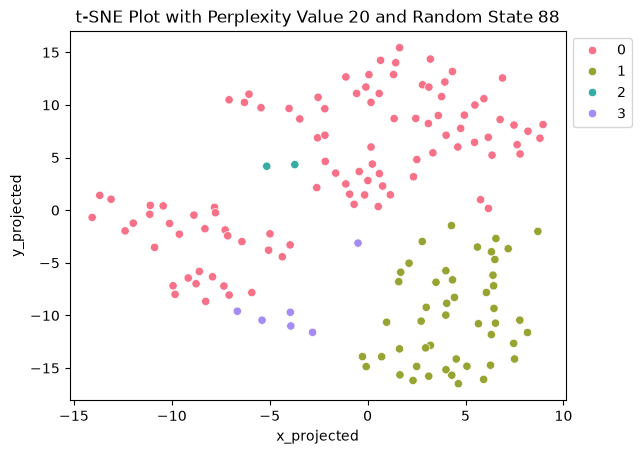

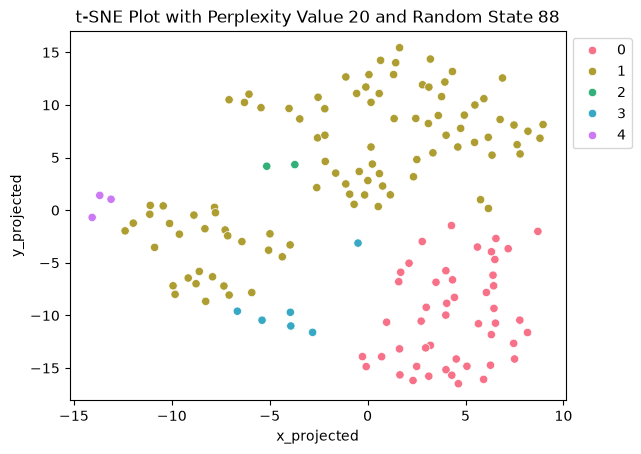

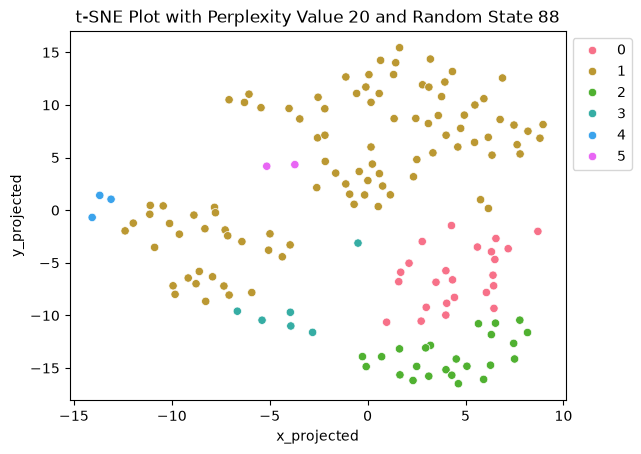

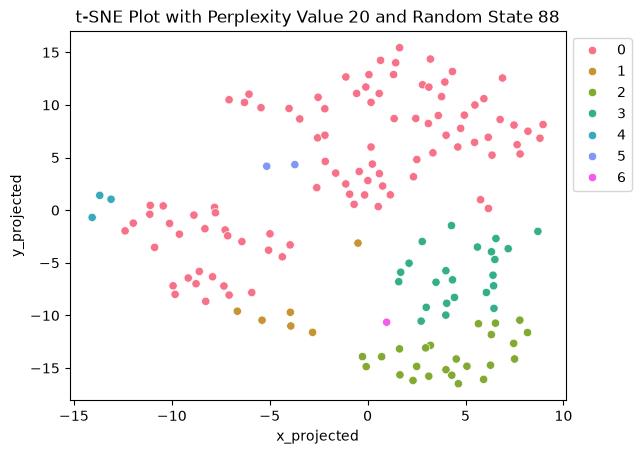

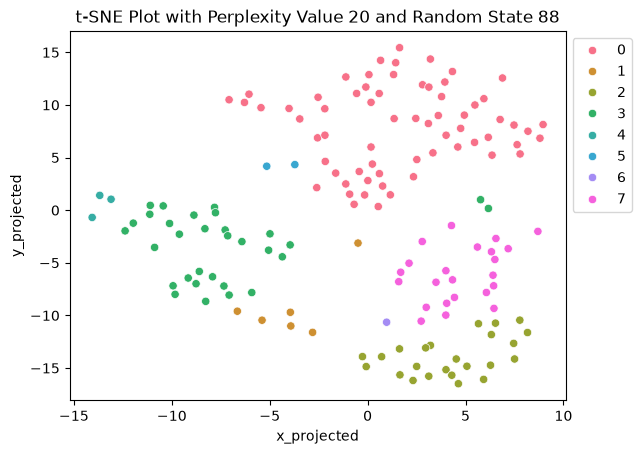

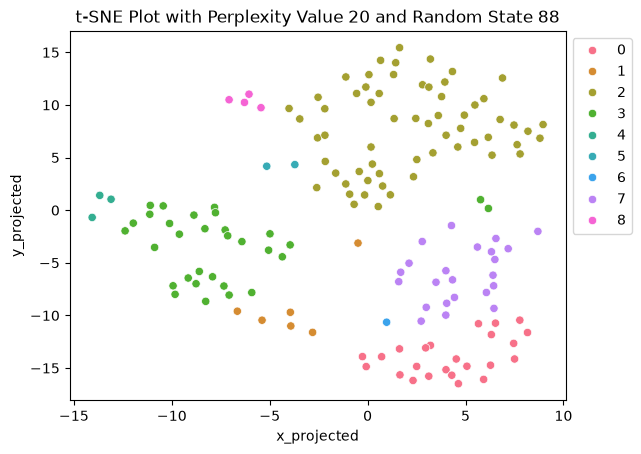

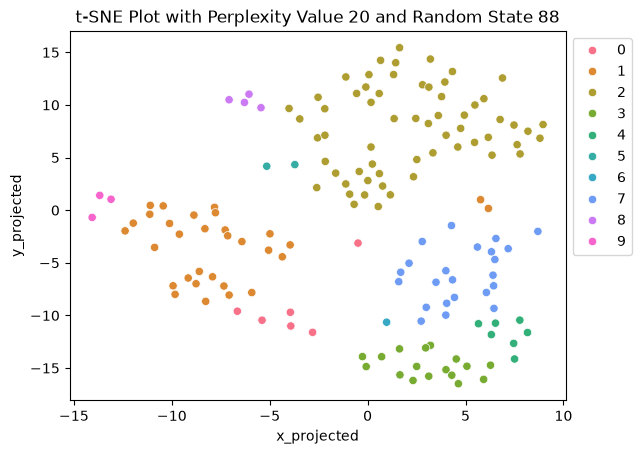

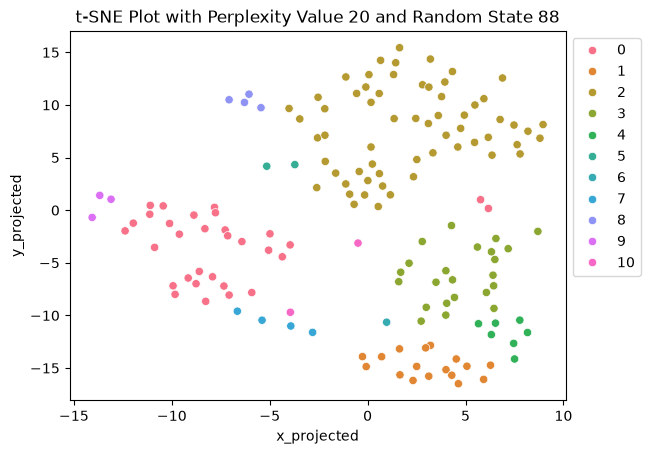

In [37]:
for k in range(2, 12):
    hac = AgglomerativeClustering(n_clusters=k, linkage='average')
    df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])

    sns.scatterplot(x='x_projected', y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Perplexity Value %s and Random State %s' % (20, 88))
    plt.legend(bbox_to_anchor=(1, 1))
    plt.show()

## 8. Hierarchical Agglomerative Clustering with Ward's Linkage

Let's try out hierarchical agglomerative clustering with Ward's linkage.

### 8.1.  Dendrogram

Create a dendrogram using hierarchical agglomerative clustering with Ward's linkage for the dataset. 
* Label the points with the 'City' column.
* Make sure you are able to read the city labels in your dendrogram.

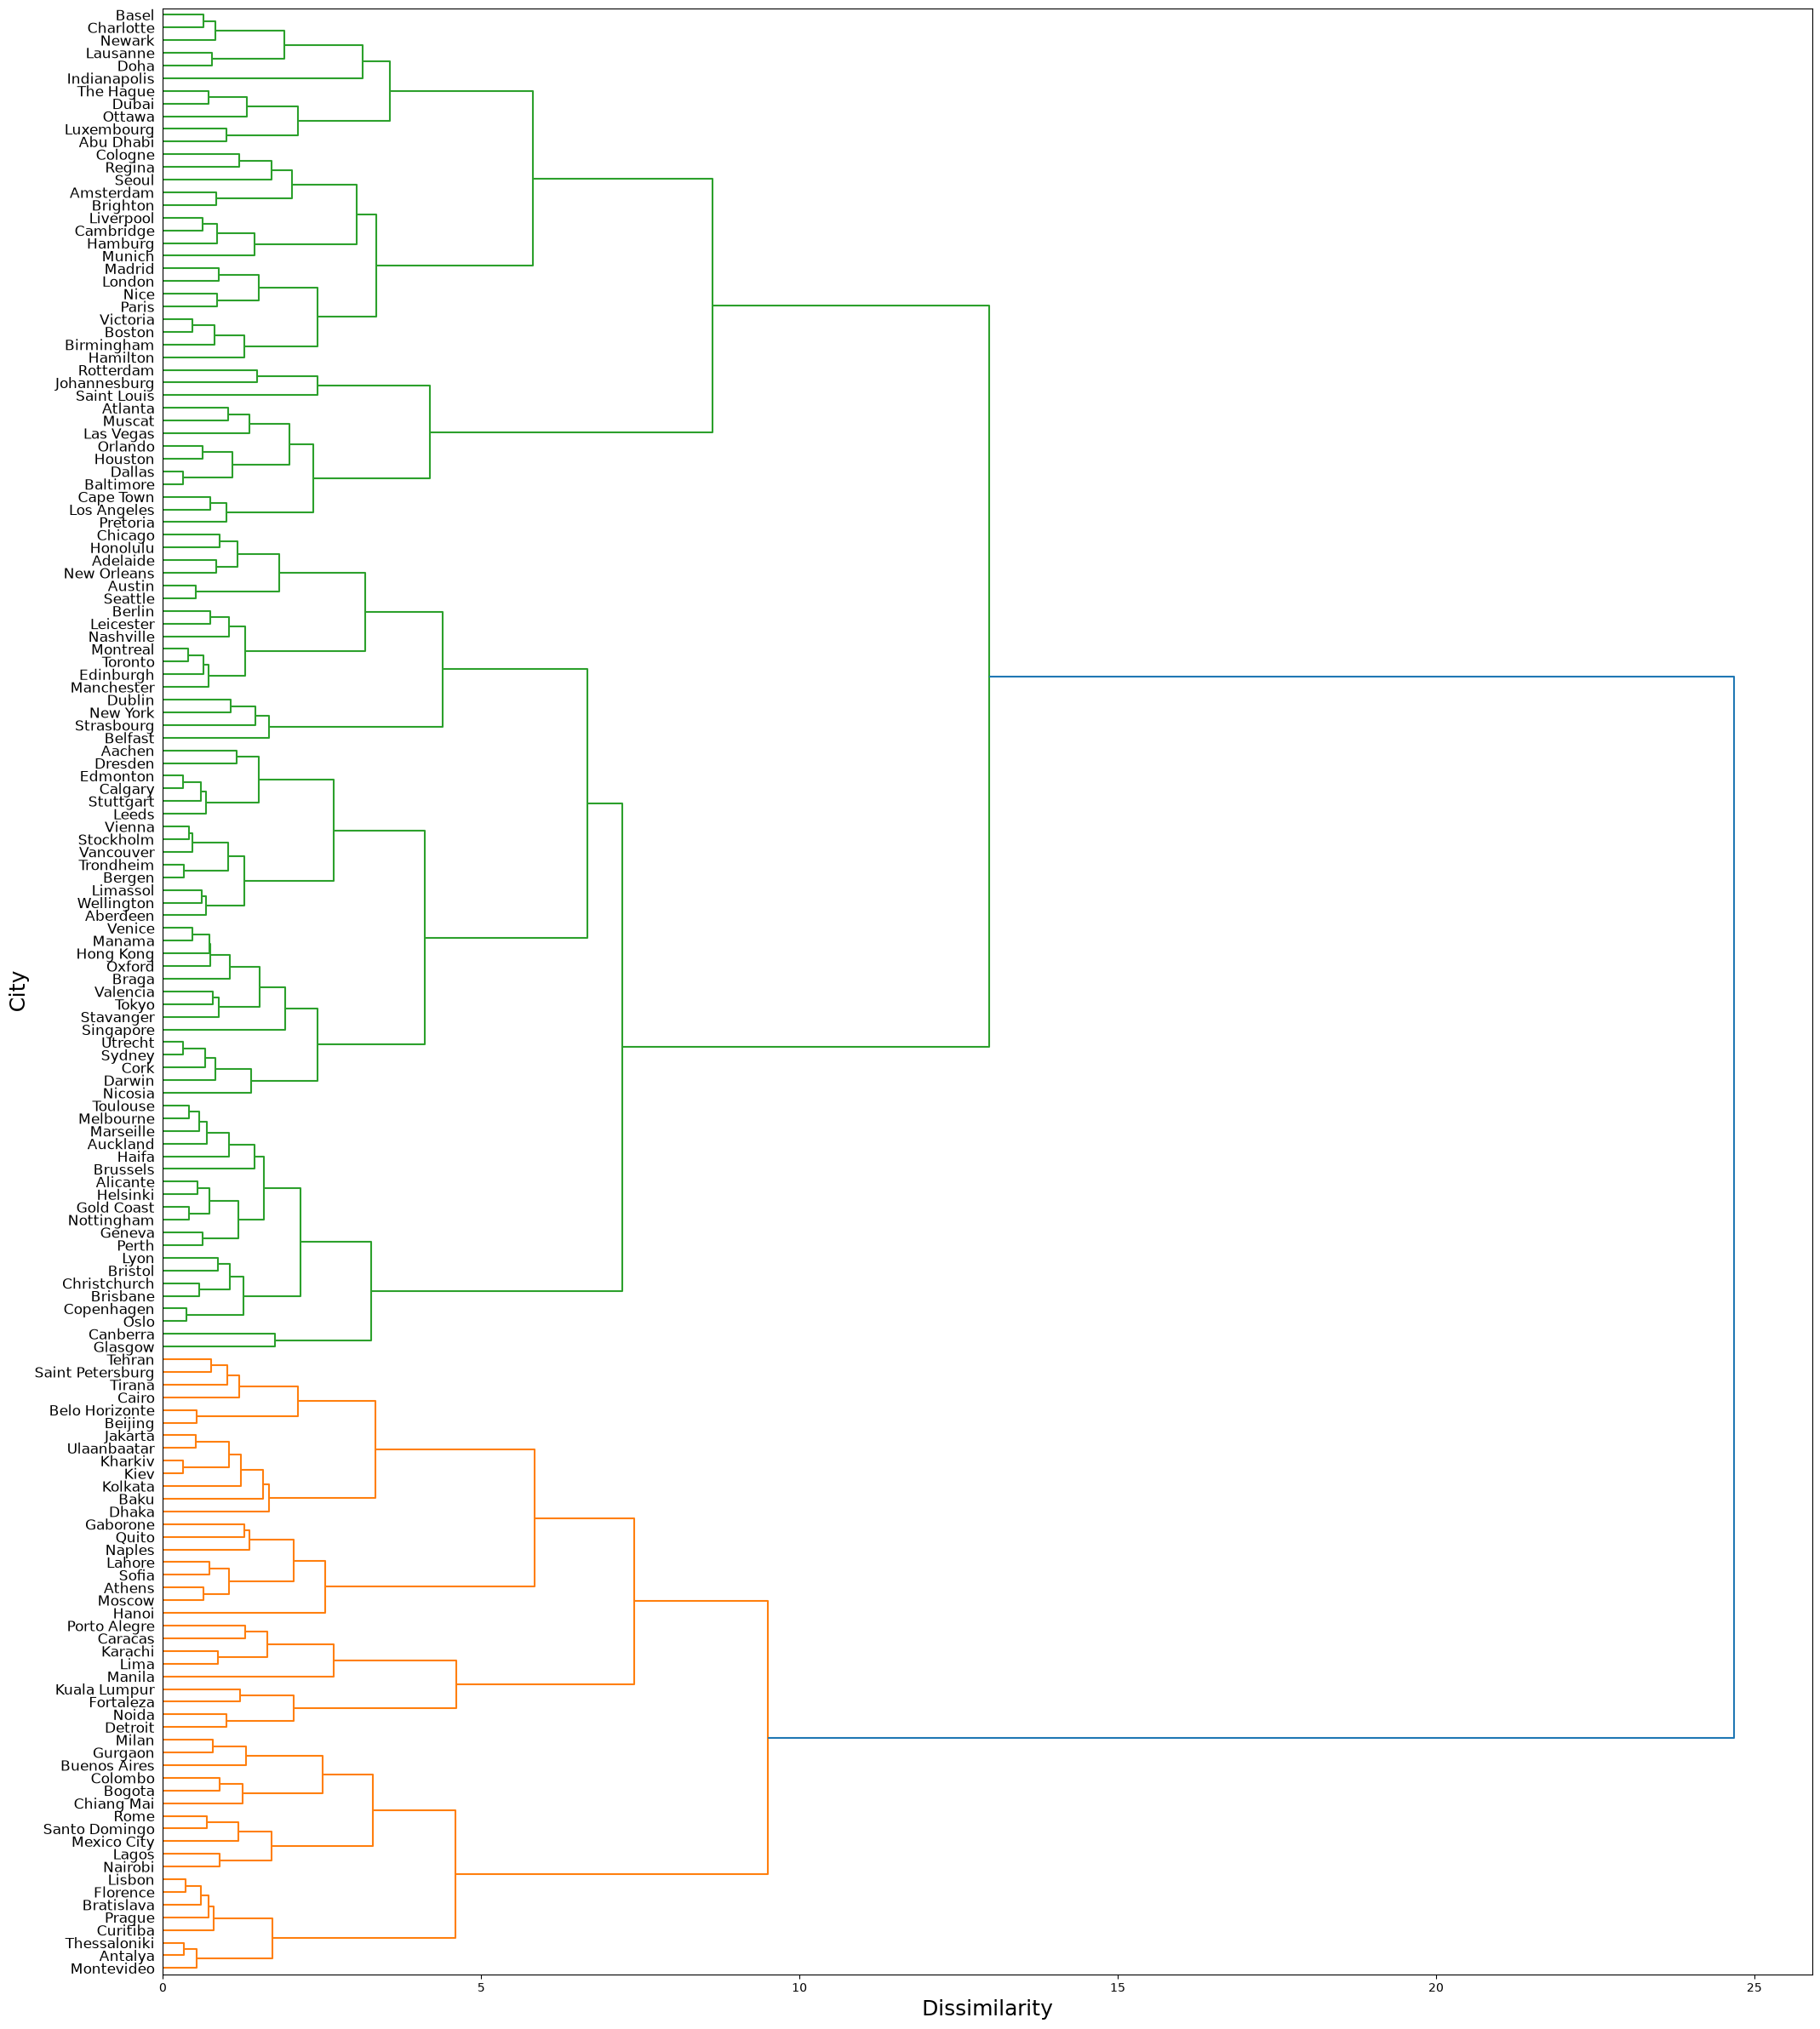

In [40]:
dm = pdist(df[num_cols], metric='euclidean')
Z = linkage(dm, method='ward')

fig, ax = plt.subplots(figsize=(25, 30))
d = dendrogram(Z, orientation='right', labels=df['City'].array, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('City', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

### 8.2. t-SNE Individual Clustering Visualization

Then for each of the clusterings with k=2,k=3,...,k=11 clusters, color code the points in your selected t-SNE plot with the respective cluster labels.

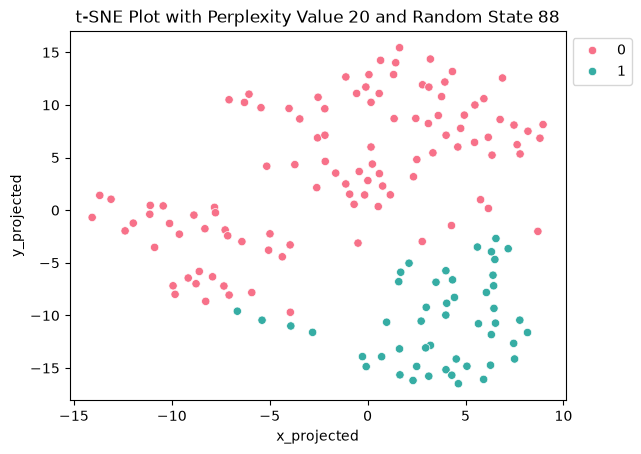

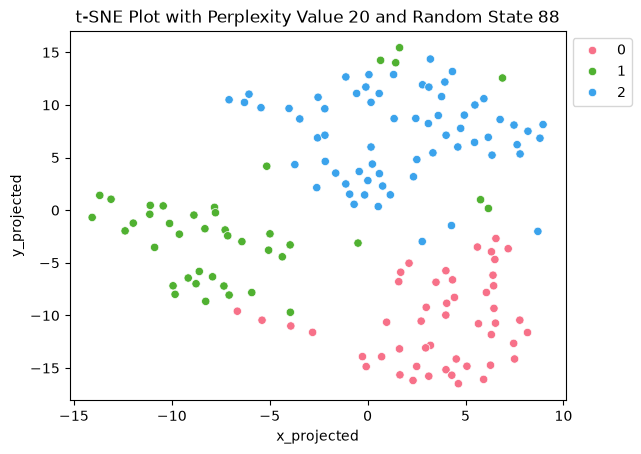

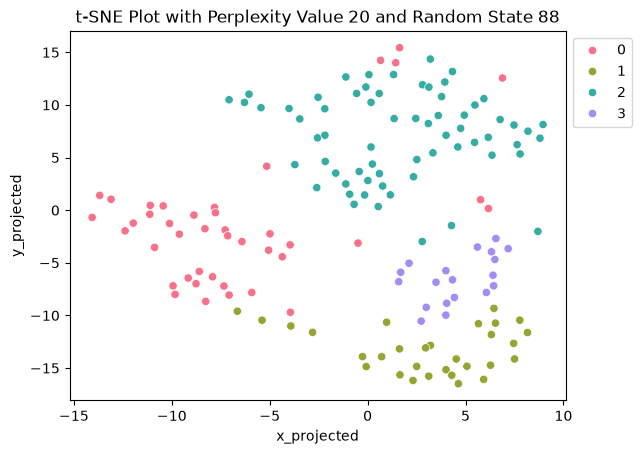

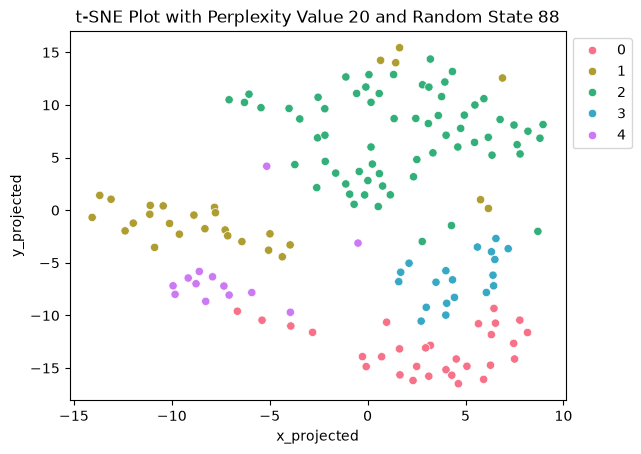

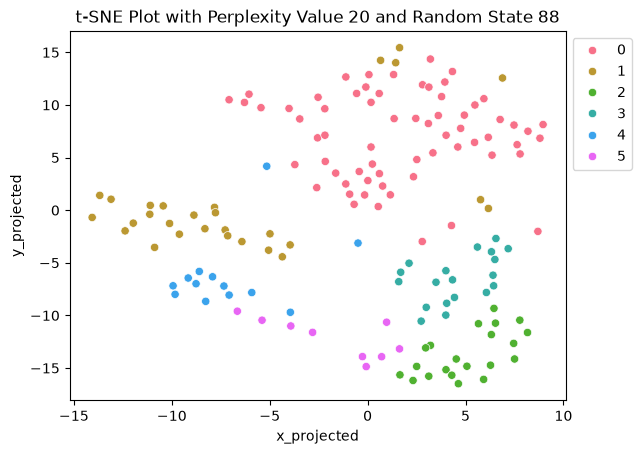

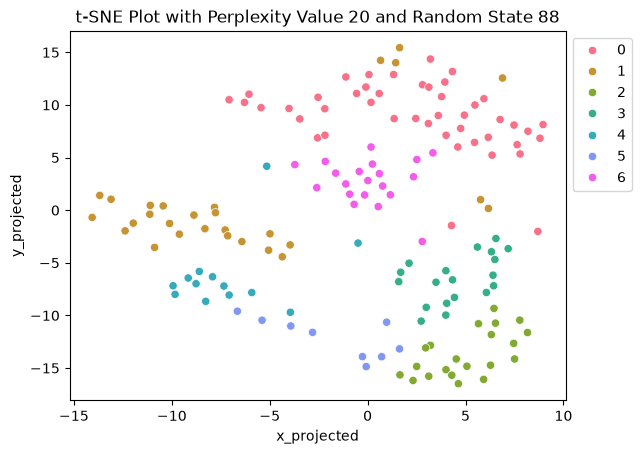

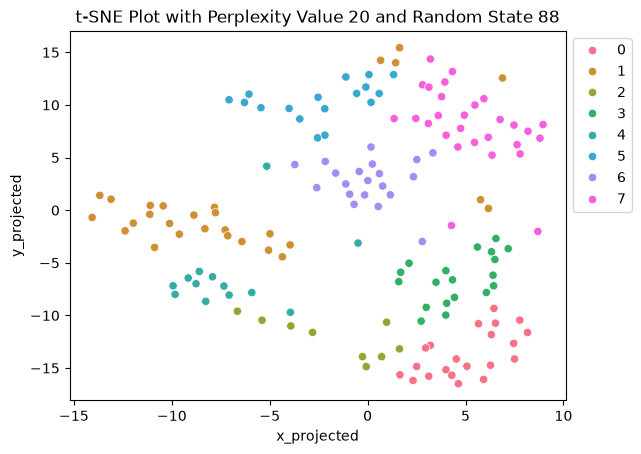

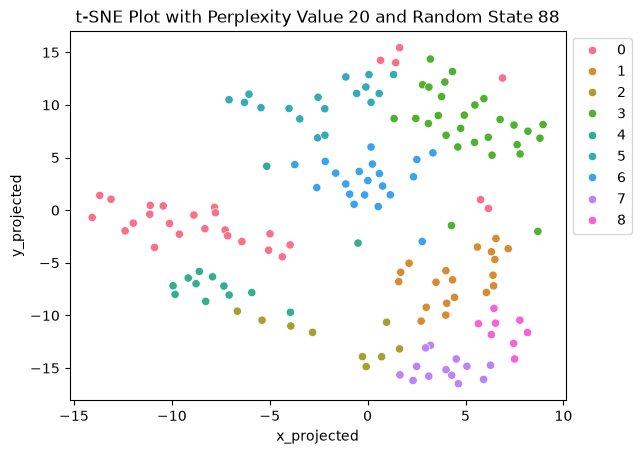

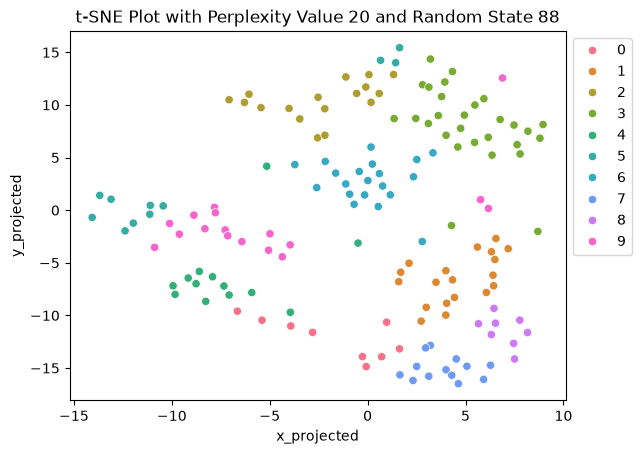

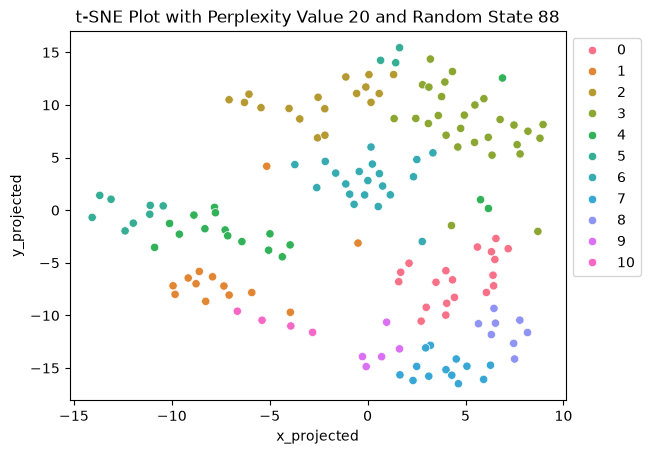

In [41]:
for k in range(2, 12):
    hac = AgglomerativeClustering(n_clusters=k, linkage='ward')
    df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])

    sns.scatterplot(x='x_projected', y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", k), data=df_combo)
    plt.title('t-SNE Plot with Perplexity Value %s and Random State %s' % (20, 88))
    plt.legend(bbox_to_anchor=(1, 1))
    plt.show()

### 8.3. Initial Clustering Assessment

#### 8.3.1. k=2

1. Which linkage function clustering (specifically with k=2 clusters) yielded the highest average silhouette score?
2. Which linkage function clustering (specifically with k=2 clusters) had the most t-SNE plot corroboration?

1. Complete linkage had the highest average silhouette score at k=2, about 0.38.

2. Complete linkage had the most t-SNE plot support because it separated the lower-right group more clearly from the other points.

#### 8.3.2. No Small Clusters

Suppose we would eventually like to use the clusters that we find to make recommendations to people looking to move. (For instance, if you live in Chicago, what other cities are similar to Chicago? Or in other words, what cities are in the same cluster as Chicago?) Because of this, we would ideally like for our clusters to have more than just a few cities in them (particularly for clusterings that are higher up on the dendrogram tree like k=2,3,4,5,6).

Which two linkage functions were the best at *not* returning small (or singleton) clusters for this dataset?

Complete linkage and Ward’s linkage were the best at avoiding small or singleton clusters. They produced larger, more balanced groups of cities.

## 9. Final Linkage Function Comparison

Our t-SNE plots may give us reason to believe that there are more than two inherent clusters. So let's explore and compare the following clusterings.

* HAC complete (k=6)
* HAC Ward's (k=5)


### 9.1. HAC complete (k=6)

1. Create a cluster sorted similarity matrix for this clustering.
2. Make sure you know where the end points of each cluster are in the cluster-sorted similarity matrix. ex: `df['clustering'].value_counts()`.
3. Also show the color-coded t-SNE plot for this clustering again here as well.

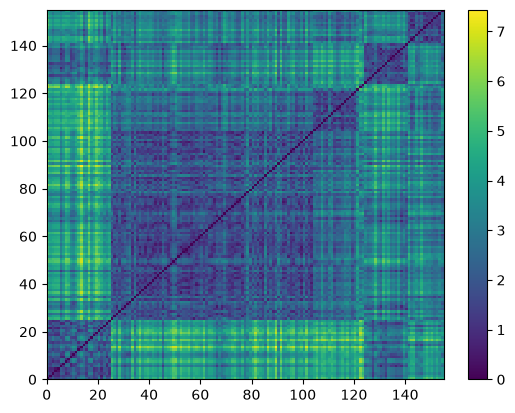

Cluster 0 : 0 to 24
Cluster 1 : 25 to 103
Cluster 2 : 104 to 121
Cluster 3 : 122 to 123
Cluster 4 : 124 to 140
Cluster 5 : 141 to 154


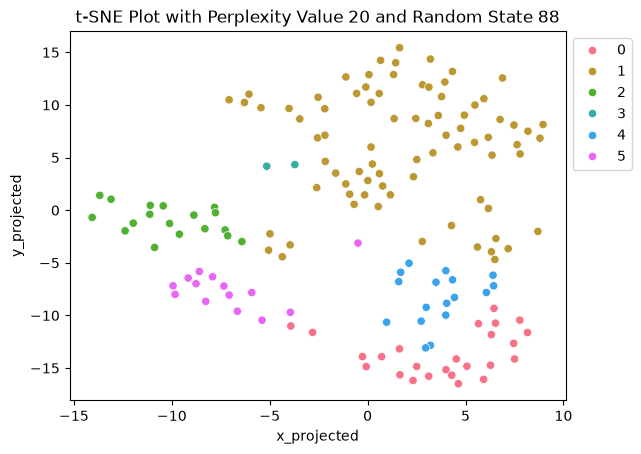

In [42]:
from scipy.spatial.distance import pdist, squareform

hac = AgglomerativeClustering(n_clusters=6, linkage='complete')
df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])

df_sort = df[num_cols].copy()
df_sort['cluster'] = hac.labels_
df_sort = df_sort.sort_values(by='cluster')
df_sort = df_sort.drop('cluster', axis=1)

dist_mat = squareform(pdist(df_sort))

plt.pcolormesh(dist_mat)
plt.colorbar()
plt.show()

start = 0
for cluster in range(6):
    n = sum(hac.labels_ == cluster)
    print("Cluster", cluster, ":", start, "to", start + n - 1)
    start = start + n

sns.scatterplot(x='x_projected', y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", 6), data=df_combo)
plt.title('t-SNE Plot with Perplexity Value %s and Random State %s' % (20, 88))
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

### 9.2. HAC Ward's (k=5)

1. Create a cluster sorted similarity matrix for this clustering.
2. Make sure you know where the end points of each cluster are in the cluster-sorted similarity matrix. ex: `df['clustering'].value_counts()`.
3. Also show the color-coded t-SNE plot for this clustering again here as well.

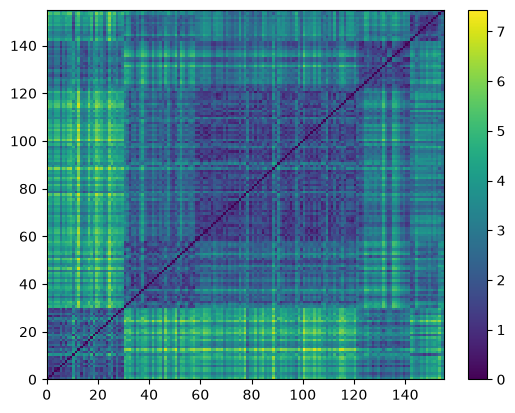

Cluster 0 : 0 to 29
Cluster 1 : 30 to 57
Cluster 2 : 58 to 122
Cluster 3 : 123 to 141
Cluster 4 : 142 to 154


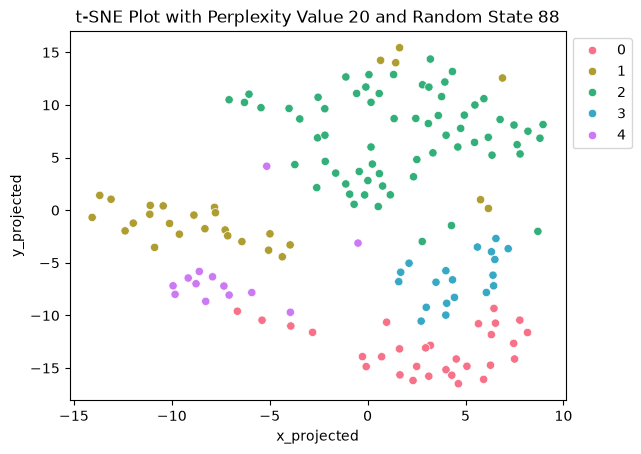

In [43]:
hac = AgglomerativeClustering(n_clusters=5, linkage='ward')
df_combo['predicted_cluster'] = hac.fit_predict(df[num_cols])

df_sort = df[num_cols].copy()
df_sort['cluster'] = hac.labels_
df_sort = df_sort.sort_values(by='cluster')
df_sort = df_sort.drop('cluster', axis=1)

dist_mat = squareform(pdist(df_sort))

plt.pcolormesh(dist_mat)
plt.colorbar()
plt.show()

start = 0
for cluster in range(5):
    n = sum(hac.labels_ == cluster)
    print("Cluster", cluster, ":", start, "to", start + n - 1)
    start = start + n

sns.scatterplot(x='x_projected', y='y_projected', hue='predicted_cluster', palette=sns.color_palette("husl", 5), data=df_combo)
plt.title('t-SNE Plot with Perplexity Value %s and Random State %s' % (20, 88))
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

### 9.3. Final Comparison

1. Which of these clusterings (HAC Complete, k=6) vs. (HAC Ward's k=5) has the highest average silhouette score?
2. Do either of these clusterings (HAC Complete, k=6) vs. (HAC Ward's k=5) exhibit a dramatically better block diagonal form in the cluster-sorted similarity matrices?
3. Did either of these clusterings (HAC Complete, k=6) vs. (HAC Ward's k=5) exhibit dramatically more alignment with the t-SNE plot suggested clusters overall?

1. Complete linkage with k=6 had the higher average silhouette score, about 0.24 compared to 0.23 for Ward's with k=5

2. No, both matrices showed similar block diagonal patterns. Neither is much better than the other.

3. No, both clusterings matched the t-SNE groups fairly similarly, although Ward’s avoided the tiny cluster produced by complete linkage.

## 10. Post-Cluster Analysis (HAC Complete Linkage)


Let's choose to examine some of the clusterings found with HAC with complete linkage.

### 10.1. Two Most Distinct Clusters

1. What *cities* were in the two most distinct clusters found by this clustering algorithm (ie. the two final clusters that were merged together last in the complete linkage dendrogram)? `Hint: See the end of the Unit 5 ipynb for how to row filter a dataframe.`
2. What attribute values characterize these two most distinct clusters found by this clustering algorithm (ie. the two clusters that were merged together last)? `Hint: Make a side-by-side boxplot visualization for each attribute and the clustering with k=2 clusters.`



1. Cluster 0 contained 113 cities, including Hong Kong, Tokyo.... Cluster 1 contained 42 cities, including Santo Domingo, Beijing...

2. Cluster 0 generally had higher purchasing power, better health care, higher quality of life, and lower pollution and crime ratings. Cluster 1 generally showed the opposite pattern. Purchasing power and quality of life showed the clearest differences.

In [44]:
hac = AgglomerativeClustering(n_clusters=2, linkage='complete')
df['predicted_cluster'] = hac.fit_predict(df[num_cols])

In [45]:
df[df['predicted_cluster'] == 0]['City']

3       Hong Kong
4           Tokyo
5           Seoul
9          Prague
10     Bratislava
          ...    
150          Nice
151        Vienna
152        Aachen
153       Utrecht
154     Marseille
Name: City, Length: 113, dtype: str

In [46]:
df[df['predicted_cluster'] == 1]['City']

0         Santo Domingo
1                  Baku
2               Nairobi
6               Beijing
7           Ulaanbaatar
8                Moscow
11     Saint Petersburg
12                 Kiev
13                Sofia
14              Kharkiv
15          Mexico City
22               Tehran
23              Antalya
24                Cairo
88            Fortaleza
90         Buenos Aires
91           Montevideo
92              Caracas
93       Belo Horizonte
94                 Lima
95               Bogota
96         Porto Alegre
97                Quito
99              Gurgaon
100             Colombo
101               Dhaka
102             Kolkata
103             Karachi
104              Lahore
106        Kuala Lumpur
107             Jakarta
108          Chiang Mai
109              Manila
110               Hanoi
114            Gaborone
116               Milan
119                Rome
122              Naples
126              Athens
127        Thessaloniki
129              Tirana
131             

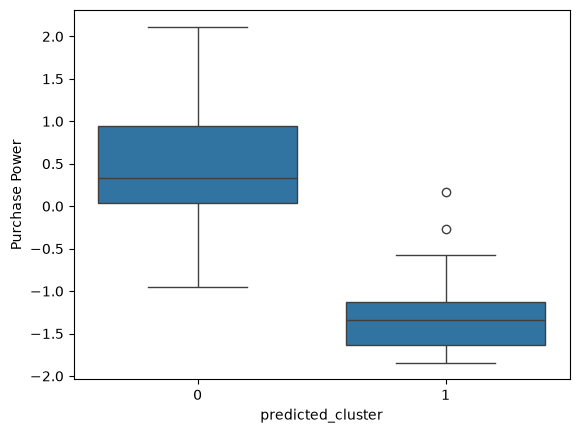

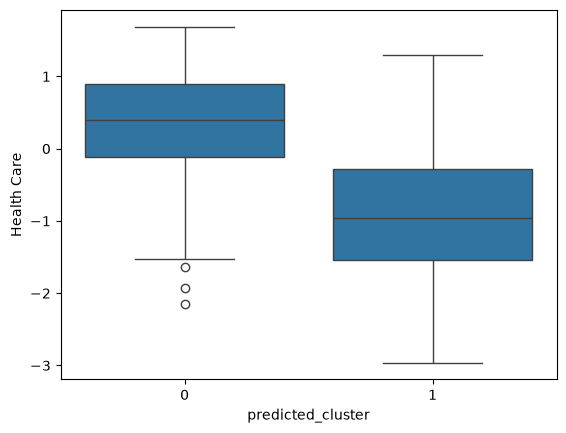

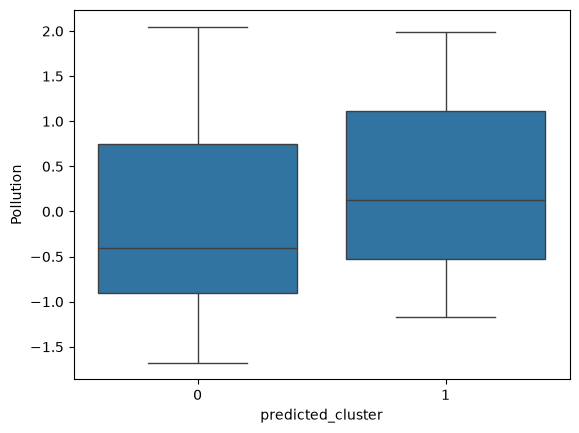

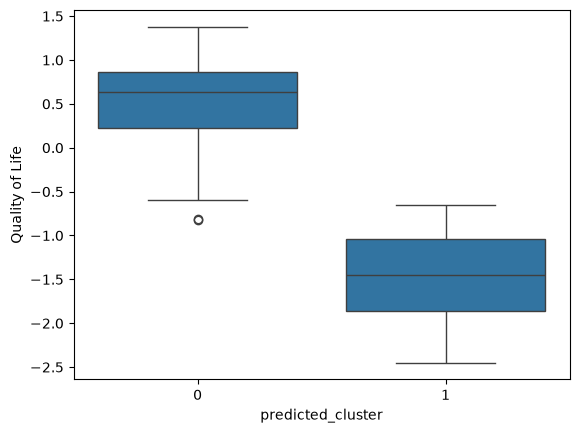

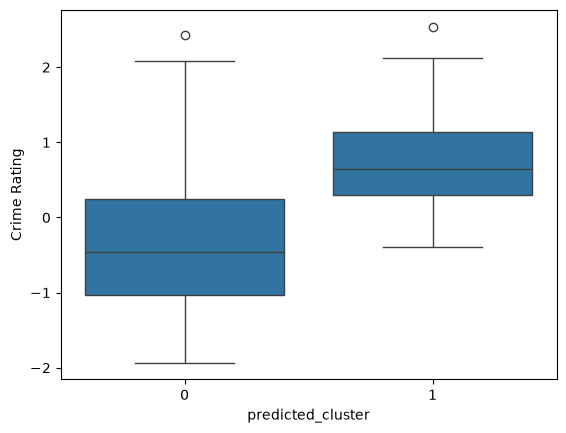

In [47]:
for col in num_cols:
    sns.boxplot(x='predicted_cluster', y=col, data=df)
    plt.show()

### 10.2. Two Second Most Distinct Clusters

1. What cluster (from #10.1) was split in moving to the clustering with k=3 clusters? What cluster labels are these two newly split clusters represented as in the k=3 clustering? (Hint: You might look at your row filtered cities lists and the dendrogram).
2. For the cluster that was split, what attributes distinguish the two resulting clusters created? `Hint: Make a side-by-side boxplot visualization for each attribute and the clustering with k=3 clusters. Focus on which attributes are distinct for these two newly formed clusters in particular.`